### **ASIGNATURA:** Gestion de proyecto de datos

### **NOMBRE PROYECTO:** Segmentación de clientes costanera Andina

### **FECHA:** 05/11/2026

### **NOMBRE INTEGRANTES:**
- Diego Améstica
- Agustín Cáceres
- Gino Andrades



## Objetivo general

Desarrollar un modelo de segmentación no supervisado basado en machine learning para analizar el comportamiento de los clientes del Centro Comercial Costanera Andina, permitiendo optimizar las estrategias de marketing personalizado y la distribución comercial (tenant mix).

## Objetivos especificos

* Consolidar, limpiar y transformar las bases de datos históricas de las tarjetas de fidelización y encuestas de satisfacción del centro comercial.

* Implementar algoritmos de agrupamiento (clustering) para identificar perfiles y segmentos de clientes según sus patrones de consumo y preferencias.

* Diseñar un panel interactivo (dashboard) y un informe ejecutivo que traduzca los hallazgos del modelo en decisiones comerciales accionables para la administración.

## Problema

El Centro Comercial Costanera Andina cuenta con registros históricos de clientes, pero carece de un sistema automatizado para analizarlos. Esto genera campañas de marketing genéricas con baja conversión, desconocimiento de los nichos de visitantes más rentables y decisiones ineficientes en la asignación de espacios comerciales para los arrendatarios.

## Contexto de la data

* Muestra de trabajo: 200 clientes del archivo de referencia `Mall Customers.xlsx` (ingreso anual en k$ y puntaje de gasto de 1 a 100), usada como prueba de concepto.
* Formato: XLSX (la muestra sintética de la fase de despliegue es CSV).   
* Contexto de Datos: en el proyecto real las fuentes serían los registros de fidelización (loyalty cards) y las encuestas de satisfacción autorizadas por el cliente; este notebook usa la muestra de referencia.

## METODOLOGÍA UTILIZADA EN EL PROYECTO DE CIENCIA DE DATOS
##NOMBRE: CRISP-DM

1. Proporciona un enfoque estructurado y confiable para proyectos de ciencia de datos, facilitando el trabajo colaborativo y asegurando consistencia en los procesos.

2. Permite iterar y ajustarse a cambios en los datos, requisitos o descubrimientos durante el desarrollo del proyecto.

3. Es adaptable a cualquier industria o tipo de proyecto, lo que lo hace versátil y aplicable en diversos contextos.

4. Organiza el trabajo en seis fases claras (Comprensión del Negocio, Comprensión de los Datos, Preparación de los Datos, Modelado, Evaluación y Despliegue), simplificando la planificación y el monitoreo.

5. Garantiza que los análisis realizados estén orientados a resolver problemas relevantes y generar valor para el negocio.

5. Es uno de los estándares más utilizados en ciencia de datos, facilita la integración de equipos y el desarrollo de poryectos de ciencia de datos.

## FASES A IMPLEMENTAR DE LA METODOLOGÍA CRISP-DM
## * FASE 1: Comprensión del Negocio
## * FASE 2: Comprensión de los datos
## * FASE 3: Preparación de los datos
## * FASE 4: Modelado
## * FASE 5: Evaluación del o los modelos
## * FASE 6: Despliegue

In [1]:
# =============================================================================
# IMPORTACIÓN DE LIBRERÍAS
# =============================================================================

"""
Librerías utilizadas durante el proceso de segmentación de clientes.

Se agrupan según su función para mantener el notebook ordenado y facilitar
la identificación de dependencias.

Incluye herramientas para:

- descarga y validación del dataset;
- manipulación y análisis de datos;
- visualización;
- preprocesamiento;
- clustering mediante K-Means;
- evaluación mediante Silhouette Score;
- reducción dimensional mediante PCA;
- almacenamiento de modelos y pipelines.
"""


# =============================================================================
# 1. LIBRERÍAS ESTÁNDAR DE PYTHON
# =============================================================================

import os
import io
import hashlib
import json
import shutil
import zipfile
from pathlib import Path


# =============================================================================
# 2. DESCARGA DE DATOS
# =============================================================================

import requests


# =============================================================================
# 3. MANIPULACIÓN Y ANÁLISIS DE DATOS
# =============================================================================

import numpy as np
import pandas as pd


# =============================================================================
# 4. VISUALIZACIÓN
# =============================================================================

import matplotlib.pyplot as plt
import seaborn as sns


# =============================================================================
# 5. PREPROCESAMIENTO
# =============================================================================

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler


# =============================================================================
# 6. CLUSTERING
# =============================================================================

from sklearn.cluster import KMeans


# =============================================================================
# 7. EVALUACIÓN DEL CLUSTERING
# =============================================================================

from sklearn.metrics import silhouette_score


# =============================================================================
# 8. REDUCCIÓN DE DIMENSIONALIDAD
# =============================================================================

from sklearn.decomposition import PCA


# =============================================================================
# 9. GUARDADO DE MODELOS Y PIPELINES
# =============================================================================

import joblib


# =============================================================================
# CONFIRMACIÓN
# =============================================================================

print("=" * 70)
print("LIBRERÍAS IMPORTADAS CORRECTAMENTE")
print("=" * 70)

# Descarga automática del ZIP únicamente cuando el notebook se ejecuta en Google Colab.
try:
    from google.colab import files as colab_files
except ImportError:
    colab_files = None


LIBRERÍAS IMPORTADAS CORRECTAMENTE


## Fase 1: Comprensión del negocio

### Contexto

El Centro Comercial Costanera Andina enfrenta un desafío crítico en su estrategia comercial y de marketing: a pesar de contar con un registros históricos provenientes de tarjetas de fidelización (loyalty cards) y encuestas de satisfacción, la organización carece de una herramienta automatizada para explotarlos.

Esta limitación operativa genera consecuencias directas en la rentabilidad y en la experiencia de los visitantes:

* Campañas genéricas y baja conversión: Las acciones de marketing se despliegan de forma masiva y sin diferenciación, lo que reduce el retorno de inversión y el interés de los consumidores.

* Desconocimiento de la rentabilidad: No existe una segmentación formal que permita identificar cuáles son los nichos de visitantes más valiosos o cuáles presentan riesgo de abandono.

* Ineficiencia en el tenant mix: Las decisiones sobre la distribución comercial, asignación de espacios y atracción de nuevos arrendatarios se toman basándose en intuición en lugar de evidencia empírica derivada del comportamiento de compra.

Para resolver este problema, el proyecto busca desarrollar un modelo de segmentación basado en machine learning (K-Means) que permita a la Gerencia de Marketing y a la administración comprender los perfiles reales de sus clientes, optimizar las estrategias comerciales y respaldar la toma de decisiones estratégicas bajo un enfoque analítico y ético.

# FASE 2: Comprensión de los datos

### Descripción de la data

* Validación de la Estructura y Calidad del Dataset: Se procesó un volumen de 200 registros de clientes únicos provenientes del sistema de tarjetas de fidelización y encuestas del Centro Comercial Costanera Andina. Mediante la inspección estructural se constató la ausencia de duplicados exactos y de nulos explícitos (NaN), identificando sin embargo valores faltantes encubiertos bajo la categoría 'Unknown' en las variables cualitativas Education (13.0%) y Marital Status (7.5%), los cuales fueron retenidos para evitar la pérdida de registros válidos de ingreso y gasto.

* Perfil Demográfico y de Gasto Preliminar: Las estadísticas descriptivas revelan una muestra compuesta mayoritariamente por mujeres (56%) y personas casadas (56%), con una edad promedio de 38.85 años (rango de 18 a 70 años). Asimismo, el ingreso anual presenta una media de 60.56 k$ y el índice de gasto (Spending Score) una media de 50.20 puntos, confirmando la necesidad de aplicar un escalado formal (StandardScaler) debido a la diferencia de unidades antes de ejecutar el modelado de clustering.

* Hallazgos Clave para el Negocio y Modelado: El análisis de correlación de Pearson demostró independencia lineal general entre las variables numéricas, descartando problemas de multicolinealidad. No obstante, el cruce multivariado entre el ingreso anual y el índice de gasto reveló visualmente 5 clústeres naturales de clientes, donde los mayores niveles de gasto se concentran en visitantes jóvenes (20 a 40 años). Esto valida de forma empírica la aplicación del algoritmo K-Means.

* Consideraciones Éticas y de Privacidad: Conforme a la legislación vigente (Ley 19.628 de Protección de la Vida Privada) y las directrices del proyecto, se eliminó el identificador directo (CustomerID) y se trabaja con datos seudonimizados y se determinó que las variables demográficas sensibles no se utilizarán para tarificación discriminatoria, sino exclusivamente para perfilar y auditar la equidad de los grupos resultantes.

In [2]:
# 1. Usar la URL RAW (apunta directamente a los bytes del archivo .xlsx)
url_raw = "https://raw.githubusercontent.com/YorkiOprogramador/costanera_andina/main/data/Mall%20Customers.xlsx"

respuesta = requests.get(url_raw)
respuesta.raise_for_status()  # Verifica que la descarga sea exitosa (código 200)

hash_calculado = hashlib.sha256(respuesta.content).hexdigest()
print("Hash real del archivo Excel:", hash_calculado)

Hash real del archivo Excel: ad3af9555a4499bac64031eb8980d4f389c4a94dcddbc6976f5915d6879c36a3


In [3]:
"""
Script para la descarga y validación criptográfica de un set de datos.

Este bloque de código obtiene un archivo Excel (.xlsx) directamente desde un
repositorio de GitHub en su formato Raw. Antes de cargarlo en un
DataFrame de Pandas, utiliza la librería hashlib para generar un
hash SHA-256 del contenido descargado y lo compara con un hash de
referencia (previamente auditado).

El objetivo es garantizar la integridad completa del archivo,
asegurando que los datos no hayan sido alterados, corrompidos ni
manipulados externamente, previniendo así la ejecución de modelos
sesgados o vulnerados.
"""
# 1. Configuración de la URL en formato RAW
url_raw = "https://raw.githubusercontent.com/YorkiOprogramador/costanera_andina/main/data/Mall%20Customers.xlsx"

# 2. Define tu Hash esperado
hash_esperado = "ad3af9555a4499bac64031eb8980d4f389c4a94dcddbc6976f5915d6879c36a3"  # hash auditado y fijado (obtenido en la celda anterior)

# 3. Obtener los bytes crudos del archivo desde la web
respuesta = requests.get(url_raw)
respuesta.raise_for_status()
contenido_crudo = respuesta.content

# 4. Generar el Hash Criptográfico (SHA-256) del archivo
hash_actual = hashlib.sha256(contenido_crudo).hexdigest()

# 5. Validación de Seguridad y lectura de archivo binario Excel (.xlsx)
if hash_actual == hash_esperado:
    print("Integridad verificada: El archivo es auténtico y no ha sido modificado.")
    # Leemos los bytes binarios con BytesIO y read_excel
    df = pd.read_excel(io.BytesIO(contenido_crudo))
    display(df)
else:
    print("ALERTA DE SEGURIDAD: El contenido del archivo ha cambiado.")
    print(f"Hash que esperábamos: {hash_esperado}")
    print(f"Hash real obtenido:   {hash_actual}")

Integridad verificada: El archivo es auténtico y no ha sido modificado.


,CustomerID,Gender,Age,Education,Marital Status,Annual Income (k$),Spending Score (1-100)
0,1,M,19,High School,Married,15,39
1,2,M,21,Graduate,Single,15,81
2,3,F,20,Graduate,Married,16,6
3,4,F,23,High School,Unknown,16,77
4,5,F,31,Uneducated,Married,17,40
...,...,...,...,...,...,...,...
195,196,F,35,High School,Married,120,79
196,197,F,45,High School,Unknown,126,28
197,198,M,32,Uneducated,Married,126,74
198,199,M,32,High School,Married,137,18


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Education               200 non-null    object
 4   Marital Status          200 non-null    object
 5   Annual Income (k$)      200 non-null    int64 
 6   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(3)
memory usage: 11.1+ KB


In [5]:
"""
Script para detectar y analizar registros duplicados basados en 'CustomerID'.
"""

# 1. Contar el total de duplicados considerando el track id
duplicados_combinados = df.duplicated(['CustomerID']).sum()
print(f"Total de registros duplicados por CustomerID: {duplicados_combinados}")

# 2. Visualizar las filas duplicadas para entender la anomalía
# Al usar keep=False, mostramos todas las ocurrencias repetidas juntas para compararlas
df_duplicados = df[df.duplicated(subset=['CustomerID'], keep=False)]

print("\nDetalle de los primeros registros duplicados (ordenados para comparación):")
display(df_duplicados.sort_values(by=['CustomerID']).head(10))

Total de registros duplicados por CustomerID: 0

Detalle de los primeros registros duplicados (ordenados para comparación):


,CustomerID,Gender,Age,Education,Marital Status,Annual Income (k$),Spending Score (1-100)


In [6]:
# Para un DataFrame completo se utiliza nunique() para ver el conteo de valores únicos por columna
df.nunique()

,0
CustomerID,200
Gender,2
Age,51
Education,7
Marital Status,4
Annual Income (k$),64
Spending Score (1-100),84


In [7]:
df['Gender'].unique()

array(['M', 'F'], dtype=object)

In [8]:
df['Education '].unique()

array(['High School', 'Graduate', 'Uneducated', 'Unknown', 'College',
       'Post-Graduate', 'Doctorate'], dtype=object)

In [9]:
df['Marital Status'].unique()

array(['Married', 'Single', 'Unknown', 'Divorced'], dtype=object)

#### Eliminación de la columna 'CustomerID'

In [10]:
df.drop(columns=['CustomerID'], inplace=True)

In [11]:
display(df.describe().T.round(2))


,count,mean,std,min,25%,50%,75%,max
Age,200.0,38.85,13.97,18.0,28.75,36.0,49.0,70.0
Annual Income (k$),200.0,60.56,26.26,15.0,41.50,61.5,78.0,137.0
Spending Score (1-100),200.0,50.20,25.82,1.0,34.75,50.0,73.0,99.0


In [12]:
display(df.select_dtypes(include='object').describe().T.round(2))

,count,unique,top,freq
Gender,200,2,F,112
Education,200,7,Graduate,67
Marital Status,200,4,Married,112


#### Conclusiones de la Fase de Carga y Diagnóstico Inicial

**1. Qué se hizo (Acciones ejecutadas):**
* **Validación e ingesta segura:** Se descargó el dataset `Mall Customers.xlsx` directamente desde el repositorio oficial utilizando validación criptográfica (SHA-256) para asegurar la integridad e inalterabilidad de los datos.
* **Inspección estructural y limpieza inicial:** Se auditaron los tipos de datos, la presencia de valores nulos y la unicidad de los registros mediante `CustomerID`. Posteriormente, se eliminó la columna `CustomerID` por tratarse de un identificador secuencial sin valor predictivo ni analítico para el agrupamiento, consolidando una matriz de 200 registros y 6 variables de estudio (3 numéricas y 3 categóricas).

**2. Descubrimientos y hallazgos clave:**
* **Calidad e integridad:** El conjunto de datos presenta 200 clientes únicos sin registros duplicados ni valores nulos explícitos (`NaN`). No obstante, la inspección de categorías reveló la presencia de valores faltantes implícitos bajo la etiqueta `'Unknown'` en `Education ` y `Marital Status`, además de un espacio residual en el nombre de la columna `'Education '`.
* **Perfil estadístico preliminar:**
  * *Variables numéricas:* La edad de los visitantes oscila entre 18 y 70 años (media de 38.85 años); el ingreso anual varía entre 15 y 137 k$ (media de 60.56 k$); y el `Spending Score` abarca de 1 a 99 puntos (media de 50.20 y mediana de 50.0). La diferencia en las unidades de medida confirma la necesidad de escalar los datos antes de modelar.
  * *Variables demográficas:* Se observa una mayor representación de clientas mujeres (`F` con 112 registros, equivalente al 56%), personas casadas (`Married` con 112 registros, 56%) y con nivel educacional universitario (`Graduate` con 67 registros, 33.5%).

**3. Pasos a seguir:**
* Desarrollar el **Análisis Exploratorio de Datos (EDA)** visual para examinar la distribución de las variables, detectar posibles valores atípicos (*outliers*) y evaluar la relación entre el ingreso anual, la edad y el puntaje de gasto.
* Construir el **pipeline de preprocesamiento** (imputación preventiva y estandarización con `StandardScaler`) para entrenar el algoritmo **K-Means**, reservando las variables demográficas (`Gender`, `Education`, `Marital Status`) para la caracterización y auditoría ética de los segmentos.


#### EDA

In [13]:
# =============================================================================
# 2.1 NORMALIZACIÓN DE COLUMNAS Y DETECCIÓN DE NULOS ENCUBIERTOS ("Unknown")
# =============================================================================

# 1. Eliminar espacios en blanco residuales en los nombres de las columnas (ej. 'Education ')
df.columns = df.columns.str.strip()
print("Columnas normalizadas:", df.columns.tolist())
print("-" * 70)

# 2. Definir listas de variables según su naturaleza
cat_cols = ['Gender', 'Education', 'Marital Status']
num_cols = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']

# 3. Auditar frecuencia absoluta y porcentual de cada categoría (buscando 'Unknown')
for col in cat_cols:
    conteo = df[col].value_counts()
    porcentaje = (df[col].value_counts(normalize=True) * 100).round(2)
    resumen_cat = pd.DataFrame({'Frecuencia': conteo, 'Porcentaje (%)': porcentaje})
    print(f"\nDetalle de la variable '{col}':")
    display(resumen_cat)

Columnas normalizadas: ['Gender', 'Age', 'Education', 'Marital Status', 'Annual Income (k$)', 'Spending Score (1-100)']
----------------------------------------------------------------------

Detalle de la variable 'Gender':


,Frecuencia,Porcentaje (%)
Gender,,
F,112,56.0
M,88,44.0



Detalle de la variable 'Education':


,Frecuencia,Porcentaje (%)
Education,,
Graduate,67,33.5
High School,40,20.0
Uneducated,31,15.5
Unknown,26,13.0
College,17,8.5
Doctorate,11,5.5
Post-Graduate,8,4.0



Detalle de la variable 'Marital Status':


,Frecuencia,Porcentaje (%)
Marital Status,,
Married,112,56.0
Single,61,30.5
Unknown,15,7.5
Divorced,12,6.0


**Interpretación de calidad de variables categóricas:**
* Se normalizaron los encabezados del DataFrame, corrigiendo el espacio final en la columna `Education`.
* Aunque el diagnóstico técnico (`df.info()`) indicó cero valores nulos (`NaN`), la auditoría semántica revela **datos faltantes encubiertos** registrados como `'Unknown'` en `Education` (26 casos, 13.0%) y en `Marital Status` (15 casos, 7.5%).
* Dado que estas variables demográficas se reservan exclusivamente para perfilar y auditar equidad en los segmentos (y no ingresan a la distancia matemática de K-Means), se conserva la etiqueta `'Unknown'` para no distorsionar la muestra ni perder registros válidos de ingreso y gasto.

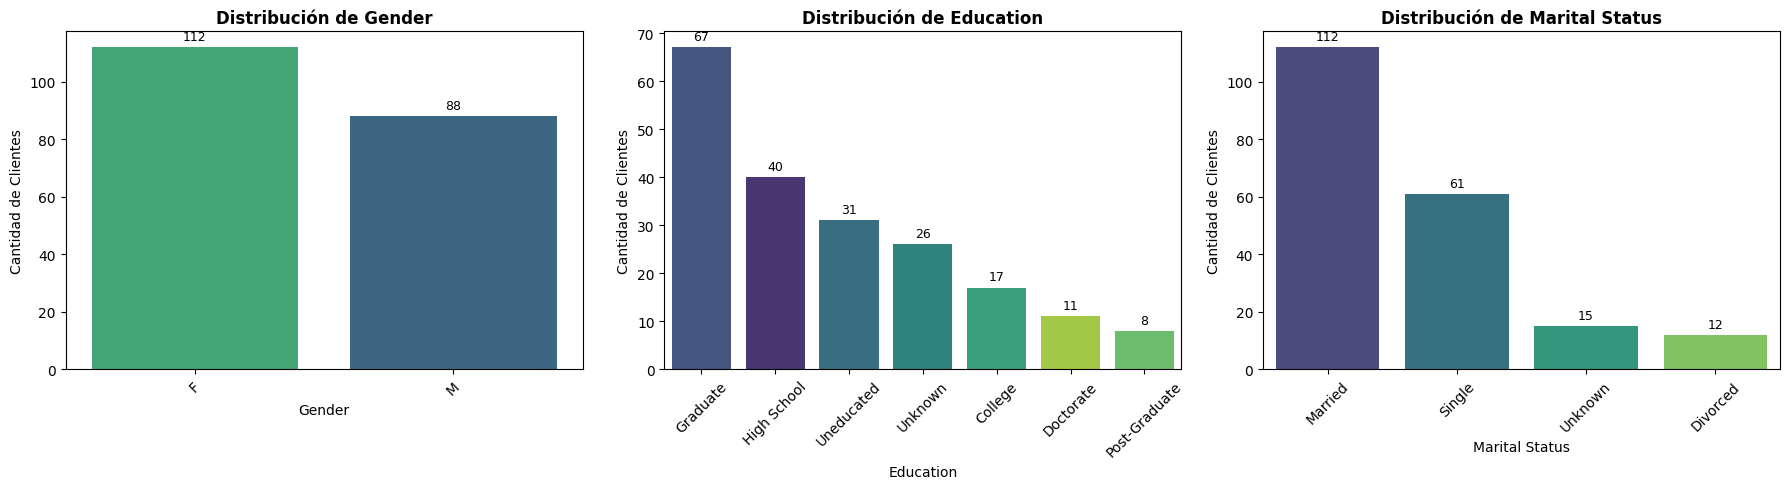

In [14]:
# =============================================================================
# 2.2 DISTRIBUCIÓN DE VARIABLES CATEGÓRICAS (AUDITORÍA DE REPRESENTATIVIDAD)
# =============================================================================

def plot_categorical_distributions(dataframe, columnas):
    """
    Genera gráficos de barras para visualizar la distribución de las variables categóricas.
    Objetivo: Identificar visualmente sesgos de representación y proporción de 'Unknown'.
    """
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for i, col in enumerate(columnas):
        orden = dataframe[col].value_counts().index
        sns.countplot(
            data=dataframe,
            x=col,
            hue=col,
            order=orden,
            ax=axes[i],
            palette='viridis',
            legend=False
        )
        axes[i].set_title(f'Distribución de {col}', fontweight='bold', fontsize=12)
        axes[i].tick_params(axis='x', rotation=45)
        axes[i].set_xlabel(col)
        axes[i].set_ylabel('Cantidad de Clientes')

        # Agregar etiquetas de datos sobre cada barra
        for container in axes[i].containers:
            axes[i].bar_label(container, fmt='%d', padding=3, fontsize=9)

    plt.tight_layout()
    plt.show()

plot_categorical_distributions(df, cat_cols)

**Interpretación demográfica:**
* **Género (`Gender`):** Existe un predominio moderado de clientas mujeres (`F`: 112 registros, 56%) frente a hombres (`M`: 88 registros, 44%).
* **Nivel Educacional (`Education`):** La mayor concentración corresponde a profesionales graduados (`Graduate`: 33.5%) y educación secundaria (`High School`: 20.0%), seguidos por `Uneducated` (15.5%) y la categoría sin información (`Unknown`: 13.0%).
* **Estado Civil (`Marital Status`):** Más de la mitad de la muestra corresponde a personas casadas (`Married`: 56.0%), seguidas por solteros (`Single`: 30.5%), sin información (`Unknown`: 7.5%) y divorciados (`Divorced`: 6.0%).

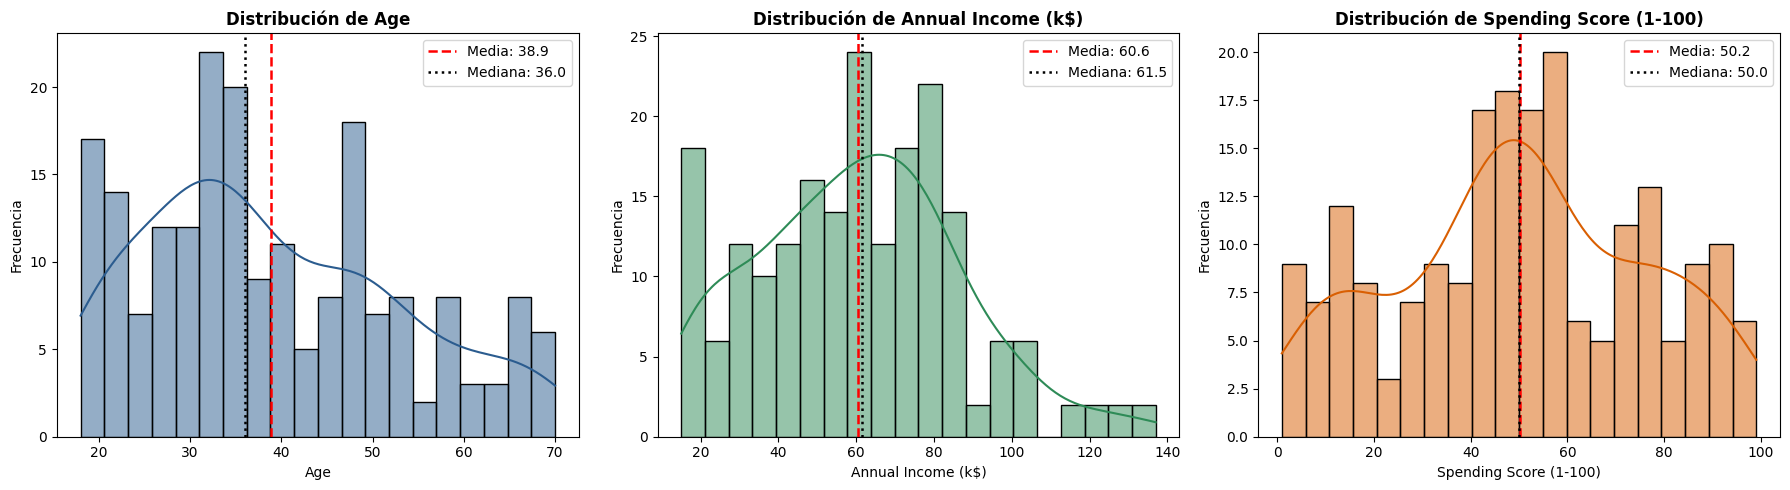

,Asimetría (Skewness),Curtosis (Kurtosis)
Age,0.486,-0.672
Annual Income (k$),0.322,-0.098
Spending Score (1-100),-0.047,-0.827


In [15]:
# =============================================================================
# 2.3 DISTRIBUCIÓN Y ASIMETRÍA DE VARIABLES NUMÉRICAS (HISTOGRAMAS + KDE)
# =============================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colores = ['#2b5c8f', '#2e8b57', '#d95f02']

for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, kde=True, bins=20, color=colores[i], ax=axes[i])

    # Líneas de referencia: Media y Mediana
    media = df[col].mean()
    mediana = df[col].median()
    axes[i].axvline(media, color='red', linestyle='--', linewidth=1.8, label=f'Media: {media:.1f}')
    axes[i].axvline(mediana, color='black', linestyle=':', linewidth=1.8, label=f'Mediana: {mediana:.1f}')

    axes[i].set_title(f'Distribución de {col}', fontweight='bold', fontsize=12)
    axes[i].set_ylabel('Frecuencia')
    axes[i].legend()

plt.tight_layout()
plt.show()

# Calcular coeficientes de asimetría (Skewness) y curtosis
metricas_forma = pd.DataFrame({
    'Asimetría (Skewness)': df[num_cols].skew().round(3),
    'Curtosis (Kurtosis)': df[num_cols].kurt().round(3)
})
display(metricas_forma)

**Interpretación de las distribuciones numéricas:**
* **`Age` (Edad):** Presenta una ligera asimetría positiva (cola hacia la derecha), con mayor concentración de visitantes entre los 28 y 40 años (mediana de 36.0 años y media de 38.85 años), pero con presencia continua de adultos mayores hasta los 70 años.
* **`Annual Income (k$)` (Ingreso Anual):** Muestra una asimetría positiva moderada debido a registros que alcanzan los 120–137 k , mientras que el grueso de los clientes se ubica entre 40 y 78 k  (media de 60.56 k$ y mediana de 61.5 k).
* **`Spending Score (1-100)` (Índice de Gasto):** Exhibe una distribución marcadamente simétrica en el centro (media de 50.2 y mediana de 50.0), pero con acumulaciones tanto en puntajes medios (40–60) como en los extremos (bajo gasto < 25 y alto gasto > 75), lo cual es un primer indicio de **subgrupos naturales** dentro de la clientela.

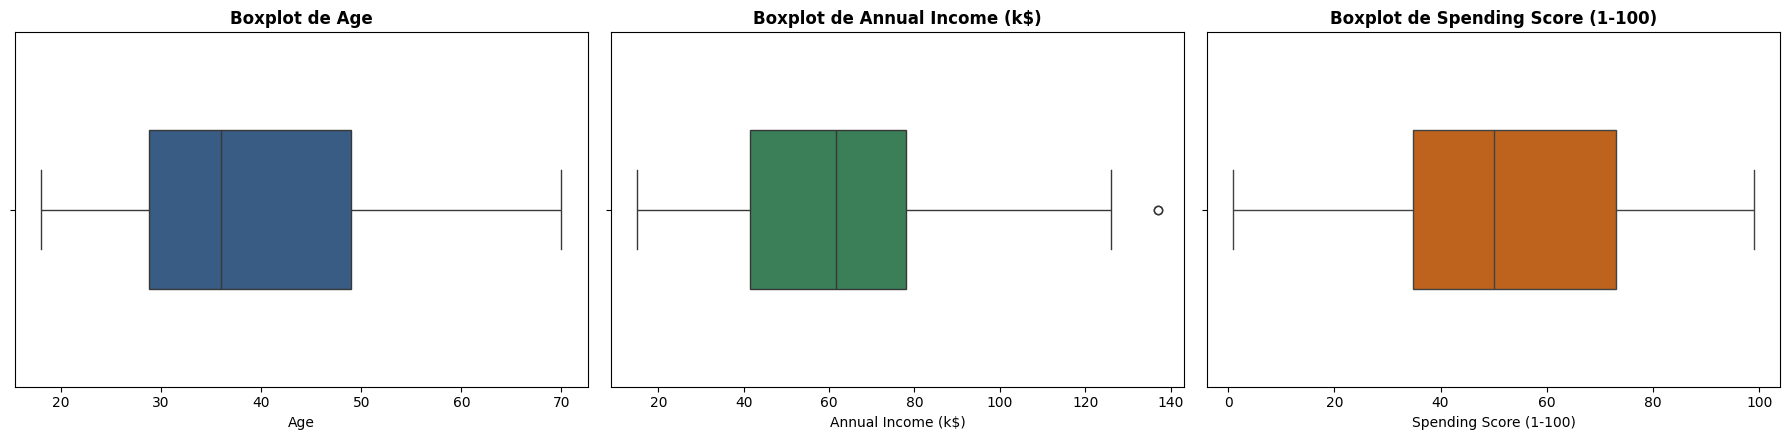

,Variable,Q1 (25%),Q3 (75%),IQR,Límite Inferior,Límite Superior,N° Outliers,% Outliers
0,Age,28.75,49.0,20.25,-1.62,79.38,0,0.0
1,Annual Income (k$),41.50,78.0,36.50,-13.25,132.75,2,1.0
2,Spending Score (1-100),34.75,73.0,38.25,-22.62,130.38,0,0.0



Registros identificados como valores extremos en 'Annual Income (k$)':


,Gender,Age,Education,Marital Status,Annual Income (k$),Spending Score (1-100)
198,M,32,High School,Married,137,18
199,M,30,College,Married,137,83


In [16]:
# =============================================================================
# 2.4 DETECCIÓN DE VALORES ATÍPICOS (OUTLIERS) MEDIANTE BOXPLOTS Y MÉTODO IQR
# =============================================================================

# 1. Visualización mediante diagramas de caja (Boxplots)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

for i, col in enumerate(num_cols):
    sns.boxplot(data=df, x=col, color=colores[i], ax=axes[i], width=0.45)
    axes[i].set_title(f'Boxplot de {col}', fontweight='bold', fontsize=12)
    axes[i].set_xlabel(col)

plt.tight_layout()
plt.show()

# 2. Cálculo matemático de Outliers mediante el Rango Intercuartílico (IQR)
resumen_outliers = []

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers_col = df[(df[col] < limite_inferior) | (df[col] > limite_superior)]

    resumen_outliers.append({
        'Variable': col,
        'Q1 (25%)': round(Q1, 2),
        'Q3 (75%)': round(Q3, 2),
        'IQR': round(IQR, 2),
        'Límite Inferior': round(limite_inferior, 2),
        'Límite Superior': round(limite_superior, 2),
        'N° Outliers': len(outliers_col),
        '% Outliers': round((len(outliers_col) / len(df)) * 100, 2)
    })

df_outliers_resumen = pd.DataFrame(resumen_outliers)
display(df_outliers_resumen)

# 3. Mostrar los registros específicos detectados como outliers en Annual Income (k$)
outliers_ingreso = df[df['Annual Income (k$)'] > (df['Annual Income (k$)'].quantile(0.75) + 1.5 * (df['Annual Income (k$)'].quantile(0.75) - df['Annual Income (k$)'].quantile(0.25)))]
print("\nRegistros identificados como valores extremos en 'Annual Income (k$)':")
display(outliers_ingreso)

**Interpretación de Outliers y Decisión Técnica/Ética:**
* Las variables `Age` y `Spending Score (1-100)` presentan **0 valores atípicos** bajo el criterio intercuartílico ($1.5 \times \text{IQR}$).
* En `Annual Income (k$)` se detectan únicamente **2 registros sobre el límite superior de 132.75 k$** (clientes con ingresos de **137 k$**, correspondientes a un perfil de bajo gasto con puntaje 18 y otro de alto gasto con puntaje 83).
* **Decisión fundamentada (Prevención de Sesgo de Exclusión Demográfica):** No se eliminarán estos 2 registros ni los clientes de tercera edad (hasta 70 años). Ambos representan comportamientos reales de subpoblaciones clave del centro comercial (visitantes de alto patrimonio y adultos mayores) y no errores de digitación. Para evitar que la magnitud de `Annual Income (k$)` distorsione las distancias euclidianas de K-Means, se aplicará estandarización (`StandardScaler`) en el pipeline de preprocesamiento.

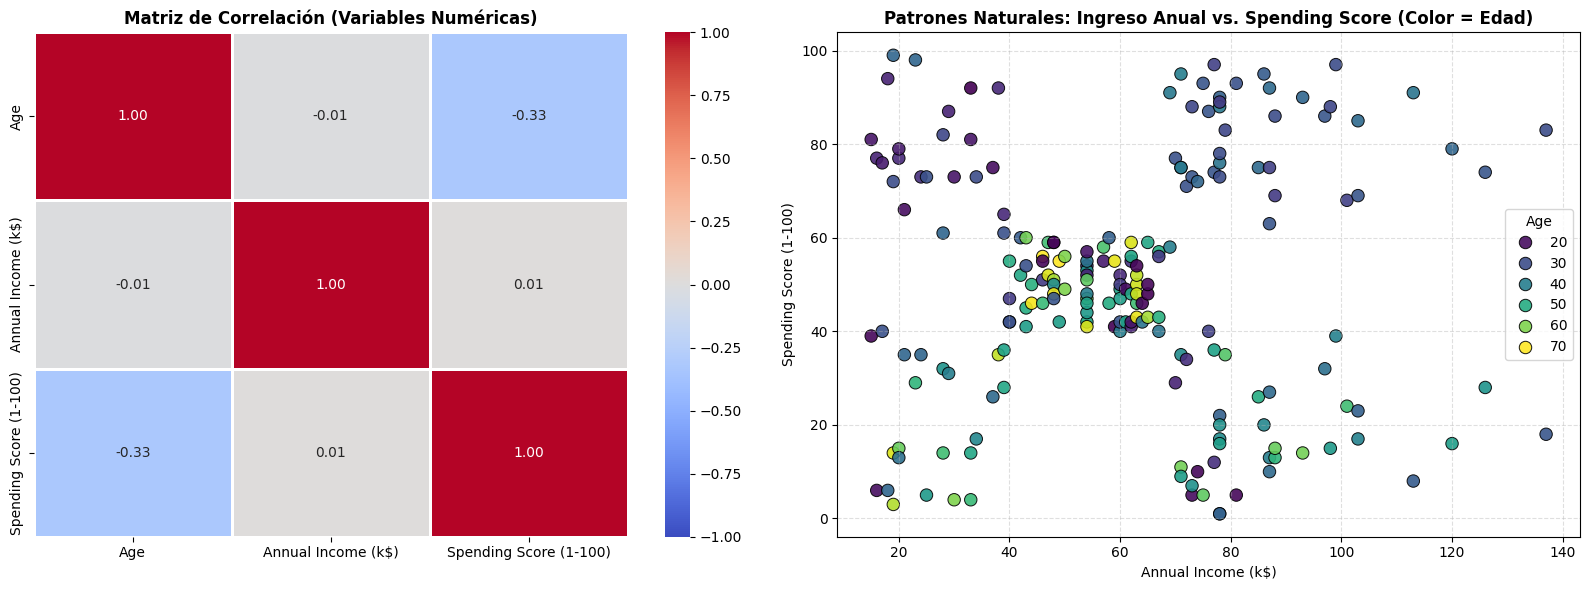

In [17]:
# =============================================================================
# 2.5 DESCUBRIMIENTO DE PATRONES Y RELACIONES MULTIVARIADAS
# =============================================================================

"""
Script para el análisis visual de correlaciones lineales y patrones geométricos
multivariados entre las variables numéricas del conjunto de datos.

Objetivo:
1. Evaluar la dependencia lineal por pares mediante una Matriz de Correlación
   de Pearson (heatmap) para descartar redundancia de información (multicolinealidad)
   antes de entrenar el algoritmo basado en distancias (K-Means).
2. Contrastar la ausencia de correlación lineal global con la existencia de
   agrupaciones no lineales en el espacio bidimensional 'Annual Income (k$)' vs.
   'Spending Score (1-100)', incorporando la variable 'Age' como tercera dimensión
   cromática para identificar los clústeres naturales de clientes.
"""

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Matriz de correlación de Pearson
corr_matrix = df[num_cols].corr()
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1,
    linewidths=1,
    ax=axes[0]
)
axes[0].set_title('Matriz de Correlación (Variables Numéricas)', fontweight='bold', fontsize=12)

# 2. Gráfico de dispersión clave: Ingreso Anual vs. Índice de Gasto (coloreado por Edad)
scatter = sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Age',
    palette='viridis',
    s=80,
    alpha=0.9,
    edgecolor='black',
    ax=axes[1]
)
axes[1].set_title('Patrones Naturales: Ingreso Anual vs. Spending Score (Color = Edad)', fontweight='bold', fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

#### Hallazgos y Conclusiones: Matriz de Correlación y Patrones Multivariados

1. **Análisis de Correlación Lineal (Mapa de Calor):**
   * **Independencia entre Ingreso y Edad/Gasto:** Las correlaciones entre `Age` e `Annual Income (-0.01)` y entre `Annual Income` y `Spending Score (0.01)` son prácticamente nulas, lo que demuestra que no existe una relación lineal directa entre ganar más dinero y gastar más o tener una edad específica.
   * **Correlación Inversa (Edad vs. Gasto):** Se observa una correlación negativa moderada de **-0.33** entre `Age` y `Spending Score (1-100)`, indicando que a mayor edad del visitante, su índice de gasto tiende a disminuir.

2. **Patrones Naturales y Agrupamiento (Gráfico de Dispersión):**
   * **Existencia de 5 Clústeres Naturales:** El cruce entre `Annual Income` y `Spending Score` revela visualmente **5 agrupaciones distintas** de clientes (bajos ingresos/bajo gasto, bajos ingresos/alto gasto, ingresos medios/gasto medio, altos ingresos/bajo gasto y altos ingresos/alto gasto).
   * **Efecto de la Variable Edad (Tercera Dimensión):** El mapeo cromático por edad confirma que los puntajes de gasto más elevados (superiores a 60-80 puntos) se concentran casi exclusivamente en los clientes más jóvenes (20 a 40 años, representados en tonos morados y azules), validando la necesidad de aplicar un modelo de segmentación no supervisado como **K-Means**.

#### Conclusiones del EDA

#### Conclusiones Generales del Análisis Exploratorio de Datos (EDA)

* **Integridad y Calidad Estructural:** El conjunto de datos analizado del Centro Comercial Costanera Andina cuenta con un volumen total de 200 registros de clientes y no presenta filas duplicadas ni valores nulos explícitos del tipo `NaN`. Tras la normalización de los encabezados, se identificó y documentó la presencia de valores faltantes implícitos o encubiertos bajo la etiqueta `'Unknown'` en las variables categóricas de educación y estado civil, los cuales se decidió conservar para evitar la pérdida de registros útiles de comportamiento.

* **Perfil Demográfico y Comportamental:** Las estadísticas descriptivas y las distribuciones demuestran que la muestra está compuesta predominantemente por mujeres (56%) y personas casadas (56%), con una edad promedio de 38.85 años. Asimismo, los ingresos anuales varían entre 15 k$ y 137 k$ (con una media de 60.56 k$) y el índice de gasto (*Spending Score*) se distribuye de 1 a 99 puntos (con una media de 50.20), evidenciando la necesidad de escalar las variables numéricas mediante `StandardScaler` antes de la fase de modelado.

* **Ausencia de Redundancia y Detección de Outliers:** El análisis de correlación lineal de Pearson demostró que las variables numéricas presentan independencia general (por ejemplo, una correlación casi nula de 0.01 entre ingresos y gasto), descartando problemas severos de multicolinealidad. Del mismo modo, la detección de valores atípicos mediante el rango intercuartílico (IQR) identificó casos extremos aislados en los ingresos, los cuales se optó por retener para prevenir el sesgo de exclusión demográfica, ya que representan comportamientos reales de alto valor patrimonial.

* **Justificación del Modelado No Supervisado:** El cruce bivariado entre el ingreso anual y el índice de gasto reveló visualmente la existencia de **5 clústeres naturales** de clientes, hallazgo que se complementa con la dimensión de la edad (donde los mayores puntajes de gasto se concentran en clientes jóvenes de 20 a 40 años). Esto valida y justifica de manera empírica la aplicación del algoritmo **K-Means** para aislar los perfiles comerciales que orientarán la estrategia de marketing y la distribución de tiendas (*tenant mix*) del centro comercial.

# FASE 3: Preparación de los datos

## Configuración del Pipeline

In [18]:
# 1. Definir las características (features) que ingresarán al modelo de clustering
features_cluster = ['Annual Income (k$)', 'Spending Score (1-100)']

# 2. Crear la matriz X_cluster a partir de tu DataFrame limpio
X_cluster = df[features_cluster]

# (Opcional) Verificar que se creó correctamente
display(X_cluster.head())

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [19]:
# =============================================================================
# PIPELINE DE PREPROCESAMIENTO PARA K-MEANS
# =============================================================================

"""
Pipeline de preprocesamiento utilizado antes de entrenar K-Means.

¿QUÉ HACE ESTE CÓDIGO?

Este bloque prepara las características numéricas seleccionadas del dataset
'Mall Customers' para que puedan ser utilizadas correctamente por el algoritmo
K-Means.

El procedimiento realiza los siguientes pasos:

1. Construye un pipeline de preprocesamiento.
2. Imputa posibles valores faltantes utilizando la mediana.
3. Estandariza todas las variables mediante `StandardScaler`.
4. Transforma el conjunto de datos numéricos.
5. Reconstruye los datos procesados como un DataFrame para conservar los
   nombres de las características.
6. Verifica que el preprocesamiento no haya generado valores NaN ni infinitos.
7. Muestra estadísticas básicas para comprobar que la estandarización se
   realizó correctamente.

¿POR QUÉ SE UTILIZA IMPUTACIÓN POR MEDIANA?

La imputación se incorpora como una medida preventiva frente a posibles
valores faltantes. Se utiliza la mediana porque es menos sensible que la
media a distribuciones asimétricas y observaciones extremas.

¿POR QUÉ SE UTILIZA STANDARDSCALER?

K-Means forma los grupos utilizando distancia euclidiana. Las variables
originales poseen escalas muy diferentes (por ejemplo, el ingreso anual en
k$ frente al Spending Score de 1 a 100). `StandardScaler`
transforma cada característica para que tenga media = 0 y desviación
estándar = 1, permitiendo que todas participen de forma comparable.
"""

# =============================================================================
# 1. CONSTRUCCIÓN DEL PREPROCESADOR
# =============================================================================

preprocessor_clustering = Pipeline(
    steps=[
        (
            'imputer',
            SimpleImputer(
                strategy='median'
            )
        ),
        (
            'scaler',
            StandardScaler()
        )
    ]
)


# =============================================================================
# 2. AJUSTE Y TRANSFORMACIÓN
# =============================================================================

X_cluster_scaled = preprocessor_clustering.fit_transform(
    X_cluster
)


# =============================================================================
# 3. RECONSTRUCCIÓN COMO DATAFRAME
# =============================================================================

X_cluster_scaled_df = pd.DataFrame(
    X_cluster_scaled,
    columns=features_cluster,
    index=X_cluster.index
)


# =============================================================================
# 4. VALIDACIONES
# =============================================================================

if np.isnan(X_cluster_scaled).any():
    raise ValueError(
        "El preprocesamiento generó valores NaN."
    )

if np.isinf(X_cluster_scaled).any():
    raise ValueError(
        "El preprocesamiento generó valores infinitos."
    )


# =============================================================================
# 5. RESULTADOS Y ESTADÍSTICAS
# =============================================================================

print("=" * 75)
print("PREPROCESAMIENTO PARA CLUSTERING COMPLETADO")
print("=" * 75)

print(
    f"\nDimensiones originales : "
    f"{X_cluster.shape}"
)

print(
    f"Dimensiones procesadas : "
    f"{X_cluster_scaled_df.shape}"
)

print("\nMedia después de StandardScaler:")
print(
    X_cluster_scaled_df
    .mean()
    .round(4)
)

print("\nDesviación estándar después de StandardScaler:")
print(
    X_cluster_scaled_df
    .std(ddof=0)
    .round(4)
)

print("\nValores mínimos estandarizados:")
print(
    X_cluster_scaled_df
    .min()
    .round(3)
)

print("\nValores máximos estandarizados:")
print(
    X_cluster_scaled_df
    .max()
    .round(3)
)

PREPROCESAMIENTO PARA CLUSTERING COMPLETADO

Dimensiones originales : (200, 2)
Dimensiones procesadas : (200, 2)

Media después de StandardScaler:
Annual Income (k$)       -0.0
Spending Score (1-100)   -0.0
dtype: float64

Desviación estándar después de StandardScaler:
Annual Income (k$)        1.0
Spending Score (1-100)    1.0
dtype: float64

Valores mínimos estandarizados:
Annual Income (k$)       -1.739
Spending Score (1-100)   -1.910
dtype: float64

Valores máximos estandarizados:
Annual Income (k$)        2.918
Spending Score (1-100)    1.894
dtype: float64


### Interpretación de Resultados del Preprocesamiento (StandardScaler)

* **Integridad de las dimensiones:** El proceso transformó exitosamente los datos manteniendo la estructura original de 200 registros y 2 variables (`Annual Income` y `Spending Score`), sin perder información ni generar valores nulos o infinitos.
* **Estandarización exitosa (Media 0 y Desviación 1):** Tras aplicar `StandardScaler`, las medias de ambas características se ajustaron a $0.0$ y sus desviaciones estándar a $1.0$. Esto garantiza que las variables queden en una escala común.
* **Control de escalas para K-Means:** Al tener unidades de medida originalmente muy distintas, la estandarización evita que la variable con mayor magnitud numérica domine desproporcionadamente el cálculo de las distancias euclidianas del algoritmo de clustering, permitiendo una agrupación justa y equilibrada.

In [20]:
# =============================================================================
# EXPORTACIÓN DE DATOS PARA SEGMENTACIÓN - CENTRO COMERCIAL COSTANERA ANDINA
# =============================================================================

"""
Exportación de los datos y objetos necesarios para reproducir posteriormente
el proceso de segmentación de clientes del Centro Comercial Costanera Andina.

¿QUÉ HACE ESTE CÓDIGO?

Este bloque guarda en archivos separados los datos utilizados durante el
clustering y el pipeline de preprocesamiento aplicado antes de entrenar
K-Means, adaptado específicamente al dataset de clientes del centro comercial.

El procedimiento realiza los siguientes pasos:

1. Crea una carpeta llamada `archivos_segmentacion` para almacenar los
   resultados exportados.

2. Genera un identificador común llamado `row_id` para mantener alineados
   los registros de los clientes entre los distintos archivos.

3. Exporta las variables numéricas de segmentación seleccionadas (ej. Ingreso Anual
   e Índice de Gasto) antes del escalamiento.

4. Exporta las mismas variables después de aplicar el pipeline de
   preprocesamiento (`SimpleImputer` + `StandardScaler`).

5. Exporta las variables demográficas y contextuales (como género, educación y
   estado civil) que no participaron directamente en la distancia matemática de
   K-Means, pero que se utilizan para interpretar y caracterizar los segmentos.

6. Guarda el pipeline de preprocesamiento mediante `joblib`.

7. Verifica mediante `assert` que todos los conjuntos exportados tengan
   exactamente la misma cantidad de observaciones.
"""

import os
import joblib

# =========================================================
# 1. CREACIÓN DE LA CARPETA DE SALIDA
# =========================================================

output_folder = 'archivos_segmentacion'

os.makedirs(
    output_folder,
    exist_ok=True
)


# =========================================================
# 2. IDENTIFICADOR COMÚN (row_id)
# =========================================================

row_id = np.arange(
    len(df)
)


# =========================================================
# 3. DATOS ORIGINALES DE SEGMENTACIÓN (Sin escalar)
# =========================================================

X_original_export = X_cluster.copy()

X_original_export.insert(
    0,
    'row_id',
    row_id
)


# =========================================================
# 4. DATOS ESCALADOS (Salida del Pipeline)
# =========================================================

X_scaled_export = X_cluster_scaled_df.copy()

X_scaled_export.insert(
    0,
    'row_id',
    row_id
)


# =========================================================
# 5. DATOS DEMOGRÁFICOS / CONTEXTUALES (Para interpretación)
# =========================================================

# Variables demográficas reservadas para perfilar los clústeres
columnas_contexto = [
    'Gender',
    'Education',
    'Marital Status',
    'Age'
]

columnas_contexto = [
    col for col in columnas_contexto
    if col in df.columns
]

contexto_segmentacion = (
    df[columnas_contexto]
    .copy()
)

contexto_segmentacion.insert(
    0,
    'row_id',
    row_id
)


# =========================================================
# 6. EXPORTACIÓN DE ARCHIVOS
# =========================================================

X_original_export.to_csv(
    os.path.join(
        output_folder,
        'X_segmentacion_original.csv'
    ),
    index=False
)

X_scaled_export.to_csv(
    os.path.join(
        output_folder,
        'X_segmentacion_escalado.csv'
    ),
    index=False
)

contexto_segmentacion.to_csv(
    os.path.join(
        output_folder,
        'contexto_segmentacion.csv'
    ),
    index=False
)

joblib.dump(
    preprocessor_clustering,
    os.path.join(
        output_folder,
        'preprocessor_clustering.joblib'
    )
)


# =========================================================
# 7. VALIDACIONES DE INTEGRIDAD
# =========================================================

assert len(X_original_export) == len(X_scaled_export), "Error en la cantidad de filas originales vs escaladas."
assert len(X_scaled_export) == len(contexto_segmentacion), "Error en la cantidad de filas escaladas vs contexto."

print("=" * 75)
print("ARCHIVOS DE SEGMENTACIÓN EXPORTADOS CORRECTAMENTE")
print("=" * 75)
print(f"\nCarpeta destino: {output_folder}/")
print("\nArchivos generados:")
print("  - X_segmentacion_original.csv")
print("  - X_segmentacion_escalado.csv")
print("  - contexto_segmentacion.csv")
print("  - preprocessor_clustering.joblib")

ARCHIVOS DE SEGMENTACIÓN EXPORTADOS CORRECTAMENTE

Carpeta destino: archivos_segmentacion/

Archivos generados:
  - X_segmentacion_original.csv
  - X_segmentacion_escalado.csv
  - contexto_segmentacion.csv
  - preprocessor_clustering.joblib


### Conclusiones de la Fase de Exportación y Cierre del Preprocesamiento

* **Consistencia y Almacenamiento Estructural:** La ejecución del bloque de exportación generó exitosamente la carpeta `archivos_segmentacion/` conteniendo de forma íntegra los conjuntos de datos originales y escalados, así como las variables de contexto demográfico y el objeto binario del pipeline de transformación (`preprocessor_clustering.joblib`).
* **Garantía de Reproducibilidad:** Mediante la asignación de un identificador común (`row_id`) y las validaciones de integridad, se aseguró que todas las tablas conserven exactamente la misma cantidad de observaciones y alineación de registros, previniendo pérdidas o desajustes de información.
* **Preparación Definitiva para el Modelado:** Con la separación limpia entre los datos numéricos listos para el cálculo de distancias y las variables de apoyo para la interpretación comercial, el entorno queda completamente preparado para entrenar y evaluar el modelo K-Means en las siguientes etapas del proyecto.

## Evaluación de K: Inercia + Silhouette

In [21]:
# =============================================================================
# EVALUACIÓN DE K PARA K-MEANS - CLIENTES COSTANERA ANDINA
# =============================================================================

"""
Evaluación de distintos valores de K para el modelo K-Means.

¿QUÉ HACE ESTE CÓDIGO?

Prueba diferentes cantidades de clusters, desde K=1 hasta K=10, con el
objetivo de comparar cómo se comporta K-Means en cada caso de segmentación.

Para cada valor de K:

1. Se crea y entrena un modelo K-Means.
2. Se asigna cada cliente a un cluster.
3. Se calcula la inercia del modelo.
4. Desde K=2 también se calcula el Silhouette Score.
5. Se guardan ambos resultados en una tabla para compararlos posteriormente.

¿QUÉ ES LA INERCIA?
La inercia mide qué tan cerca se encuentran las observaciones de su
centroide dentro de cada cluster. Una menor inercia indica grupos más compactos.

¿QUÉ ES EL SILHOUETTE SCORE?
Evalúa qué tan bien separado está un cluster de los demás (valores cercanos a 1
indican una separación óptima).
"""

# =============================================================================
# CONFIGURACIÓN
# =============================================================================

k_values = range(1, 11)
resultados_k = []

print("=" * 70)
print("EVALUACIÓN DE K-MEANS PARA SEGMENTACIÓN DE CLIENTES")
print("=" * 70)


# =============================================================================
# EVALUACIÓN
# =============================================================================

for k in k_values:

    modelo_temporal = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=20,
        max_iter=500,
        random_state=42
    )

    etiquetas = modelo_temporal.fit_predict(
        X_cluster_scaled
    )

    # -------------------------------------------------------------------------
    # INERCIA
    # -------------------------------------------------------------------------
    inercia = modelo_temporal.inertia_


    # -------------------------------------------------------------------------
    # SILHOUETTE
    # -------------------------------------------------------------------------
    # Silhouette no está definido para un único cluster
    if k >= 2:

        silhouette = silhouette_score(
            X_cluster_scaled,
            etiquetas,
            sample_size=min(
                20000,
                len(X_cluster_scaled)
            ),
            random_state=42
        )

    else:

        silhouette = np.nan


    # -------------------------------------------------------------------------
    # GUARDAR RESULTADOS
    # -------------------------------------------------------------------------
    resultados_k.append(
        {
            'k': k,
            'inercia': inercia,
            'silhouette': silhouette
        }
    )


    if k == 1:

        print(
            f"K={k:2d} | "
            f"Inercia={inercia:,.2f} | "
            f"Silhouette=No aplica"
        )

    else:

        print(
            f"K={k:2d} | "
            f"Inercia={inercia:,.2f} | "
            f"Silhouette={silhouette:.4f}"
        )


# =============================================================================
# DATAFRAME DE RESULTADOS
# =============================================================================

df_evaluacion_k = pd.DataFrame(
    resultados_k
)


EVALUACIÓN DE K-MEANS PARA SEGMENTACIÓN DE CLIENTES
K= 1 | Inercia=400.00 | Silhouette=No aplica
K= 2 | Inercia=269.69 | Silhouette=0.3213
K= 3 | Inercia=157.70 | Silhouette=0.4666
K= 4 | Inercia=108.92 | Silhouette=0.4939
K= 5 | Inercia=65.57 | Silhouette=0.5547
K= 6 | Inercia=55.06 | Silhouette=0.5399
K= 7 | Inercia=44.86 | Silhouette=0.5281
K= 8 | Inercia=37.15 | Silhouette=0.4567
K= 9 | Inercia=32.39 | Silhouette=0.4571
K=10 | Inercia=29.69 | Silhouette=0.4362


In [22]:
# =============================================================================
# DETECCIÓN AUTOMÁTICA DEL CODO (ELBOW METHOD)
# =============================================================================

k_array = (
    df_evaluacion_k['k']
    .to_numpy(dtype=float)
)

inercia_array = (
    df_evaluacion_k['inercia']
    .to_numpy(dtype=float)
)

# Normalización
k_normalizado = (
    (k_array - k_array.min())
    / (k_array.max() - k_array.min())
)

inercia_normalizada = (
    (inercia_array - inercia_array.min())
    / (inercia_array.max() - inercia_array.min())
)

puntos = np.column_stack(
    (
        k_normalizado,
        inercia_normalizada
    )
)

punto_inicial = puntos[0]
punto_final = puntos[-1]

vector_linea = (
    punto_final
    - punto_inicial
)

vector_unitario = (
    vector_linea
    / np.linalg.norm(vector_linea)
)

vectores_puntos = (
    puntos
    - punto_inicial
)

proyecciones = np.outer(
    np.dot(
        vectores_puntos,
        vector_unitario
    ),
    vector_unitario
)

distancias = np.linalg.norm(
    vectores_puntos
    - proyecciones,
    axis=1
)

indice_codo = np.argmax(
    distancias
)

K_ELBOW = int(
    k_array[indice_codo]
)

print("=" * 75)
print("RESULTADO DEL MÉTODO ELBOW - COSTANERA ANDINA")
print("=" * 75)
print(
    f"\nK sugerido por el método del codo: "
    f"{K_ELBOW}"
)
print(
    f"Distancia máxima a la línea de referencia: "
    f"{distancias[indice_codo]:.4f}"
)

RESULTADO DEL MÉTODO ELBOW - COSTANERA ANDINA

K sugerido por el método del codo: 5
Distancia máxima a la línea de referencia: 0.3243


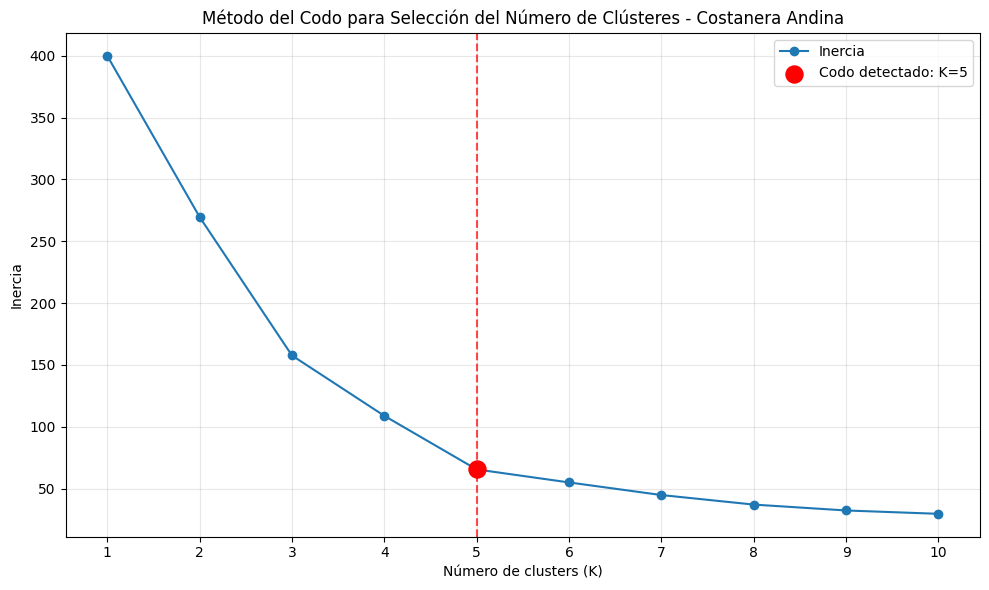

K sugerido mediante Elbow: 5


In [23]:
# =============================================================================
# VISUALIZACIÓN DEL MÉTODO ELBOW
# =============================================================================

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    df_evaluacion_k['k'],
    df_evaluacion_k['inercia'],
    marker='o',
    label='Inercia'
)

inercia_elbow = (
    df_evaluacion_k
    .loc[
        df_evaluacion_k['k'] == K_ELBOW,
        'inercia'
    ]
    .iloc[0]
)

plt.scatter(
    K_ELBOW,
    inercia_elbow,
    s=150,
    zorder=5,
    color='red',
    label=f'Codo detectado: K={K_ELBOW}'
)

plt.axvline(
    x=K_ELBOW,
    color='red',
    linestyle='--',
    alpha=0.7
)

plt.xticks(
    df_evaluacion_k['k']
)

plt.xlabel(
    'Número de clusters (K)'
)

plt.ylabel(
    'Inercia'
)

plt.title(
    'Método del Codo para Selección del Número de Clústeres - Costanera Andina'
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

print("=" * 75)
print(
    f"K sugerido mediante Elbow: "
    f"{K_ELBOW}"
)
print("=" * 75)

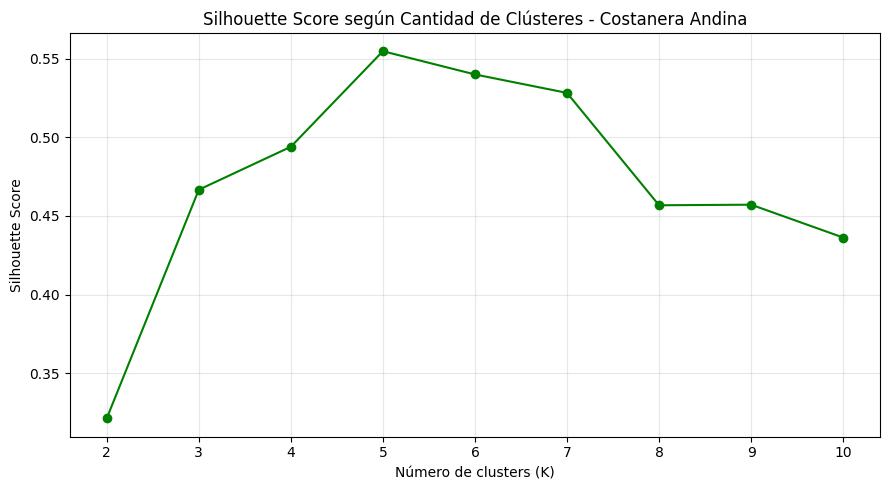

MEJOR RESULTADO SEGÚN SILHOUETTE

K = 5
Silhouette = 0.5547

Silhouette se utiliza como criterio complementario y no reemplaza la selección mediante Elbow.


In [24]:
# =============================================================================
# EVALUACIÓN Y VISUALIZACIÓN DE SILHOUETTE SCORE
# =============================================================================

df_silhouette = (
    df_evaluacion_k
    .dropna(
        subset=['silhouette']
    )
    .copy()
)

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    df_silhouette['k'],
    df_silhouette['silhouette'],
    marker='o',
    color='green'
)

plt.xticks(
    df_silhouette['k']
)

plt.xlabel(
    'Número de clusters (K)'
)

plt.ylabel(
    'Silhouette Score'
)

plt.title(
    'Silhouette Score según Cantidad de Clústeres - Costanera Andina'
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

fila_mejor = (
    df_silhouette
    .loc[
        df_silhouette['silhouette'].idxmax()
    ]
)

k_mejor_silhouette = int(
    fila_mejor['k']
)

silhouette_mejor = float(
    fila_mejor['silhouette']
)

print("=" * 70)
print("MEJOR RESULTADO SEGÚN SILHOUETTE")
print("=" * 70)

print(
    f"\nK = {k_mejor_silhouette}"
)

print(
    f"Silhouette = {silhouette_mejor:.4f}"
)

print(
    "\nSilhouette se utiliza como criterio complementario "
    "y no reemplaza la selección mediante Elbow."
)

In [25]:
# =============================================================================
# SELECCIÓN DEL NÚMERO FINAL DE CLUSTERS
# =============================================================================

"""
El número final de clusters se obtiene a partir del resultado del
Método del Codo.

En la evaluación realizada, el punto de codo fue identificado en K = 5.

Silhouette Score se utiliza como criterio complementario, pero no como
criterio exclusivo para seleccionar el número de segmentos.
"""

K_FINAL = K_ELBOW

print("=" * 70)
print("NÚMERO FINAL DE CLUSTERS")
print("=" * 70)

print(
    f"\nK seleccionado: {K_FINAL}"
)



NÚMERO FINAL DE CLUSTERS

K seleccionado: 5


### Conclusiones de la Evaluación de K (Método del Codo y Silhouette Score)

- **Análisis de Inercia y Método del Codo:** La curva de inercia mostró una disminución progresiva a medida que aumentó el número de clústeres ($K$). Mediante la detección geométrica automatizada, se identificó el punto de inflexión (*codo*) en **$K=5$**, sugiriendo un balance razonable entre la reducción de la inercia (compacidad interna de los grupos) y la simplicidad del modelo.

- **Validación mediante Silhouette Score:** El índice de silueta permitió evaluar de forma complementaria la cohesión y separación de las agrupaciones para $K \ge 2$. La métrica alcanza su máximo en **$K=5$** (0,5547), lo que indica una estructura razonable de separación y cohesión; la estabilidad y la utilidad comercial aún deben comprobarse.

- **Selección Final y Siguiente Paso:** Combinando ambos criterios cuantitativos (la inercia del método del codo y el puntaje de Silhouette) junto con la interpretabilidad comercial para el Centro Comercial Costanera Andina, **se selecciona de forma provisoria $K=5$ clústeres**. Con este resultado, se procede al entrenamiento final del modelo K-Means, la extracción de centroides y la posterior caracterización de los perfiles de clientes.

# FASE 4: Modelado

## Entrenar K-means

In [26]:
# =============================================================================
# ENTRENAMIENTO DEL MODELO K-MEANS DEFINITIVO - COSTANERA ANDINA
# =============================================================================

"""
Entrenamiento del modelo K-Means definitivo para la segmentación de clientes.

¿QUÉ HACE ESTE CÓDIGO?

Este bloque construye y entrena el modelo final de K-Means utilizando
las características seleccionadas (Ingreso Anual y Spending Score) que
fueron preparadas y estandarizadas previamente.

Pasos principales:
1. Define K_FINAL basado en el resultado de la evaluación (K_ELBOW = 5).
2. Crea el modelo K-Means con los hiperparámetros óptimos.
3. Entrena el modelo con los datos escalados (X_cluster_scaled).
4. Asigna cada cliente al clúster correspondiente mediante fit_predict().
5. Incorpora las etiquetas de clúster al DataFrame de trabajo.
6. Muestra los resultados generales (número de clústeres, inercia final e iteraciones).
"""

# Definir K_FINAL a partir de la detección previa del codo
K_FINAL = K_ELBOW  # K=5 según la evaluación final

# =============================================================================
# 1. MODELO
# =============================================================================

kmeans_final = KMeans(
    n_clusters=K_FINAL,
    init='k-means++',
    n_init=20,
    max_iter=500,
    random_state=42
)


# =============================================================================
# 2. ENTRENAMIENTO Y ASIGNACIÓN
# =============================================================================

clusters = kmeans_final.fit_predict(
    X_cluster_scaled
)


# =============================================================================
# 3. INCORPORAR RESULTADOS AL DATASET
# =============================================================================

df_resultados_cluster = (
    df.copy()
)

df_resultados_cluster[
    'cluster'
] = clusters


# =============================================================================
# 4. RESULTADOS GENERALES
# =============================================================================

print("=" * 75)
print("MODELO K-MEANS ENTRENADO - COSTANERA ANDINA")
print("=" * 75)

print(
    f"\nNúmero de clústeres (K) : "
    f"{K_FINAL}"
)

print(
    f"Inercia final          : "
    f"{kmeans_final.inertia_:,.2f}"
)

print(
    f"Iteraciones necesarias : "
    f"{kmeans_final.n_iter_}"
)
print("=" * 75)

MODELO K-MEANS ENTRENADO - COSTANERA ANDINA

Número de clústeres (K) : 5
Inercia final          : 65.57
Iteraciones necesarias : 4


### Conclusión del Entrenamiento del Modelo K-Means Definitivo

* **Número de Clústeres ($K$):** El modelo se configuró y entrenó de manera exitosa utilizando **$K = 5$** clústeres, validando consistentemente los hallazgos previos obtenidos mediante el método del codo y el índice de silueta.
* **Inercia Final:** Se obtuvo un valor de inercia final de **$65.57$**, lo que refleja un nivel sólido de compacidad interna y cercanía de las observaciones respecto a los centroides de cada segmento tras la estandarización de las variables.
* **Convergencia del Algoritmo:** El proceso de optimización convergió de forma rápida y estable en tan solo **$4$ iteraciones**, optimizado por el uso de la inicialización estratégica `k-means++`.
* **Siguiente Paso:** Con las etiquetas de clúster ya asignadas e incorporadas al conjunto de datos, se procede a extraer los centroides, analizar los mapas de calor y caracterizar formalmente los perfiles de clientes para la toma de decisiones comerciales en el Centro Comercial Costanera Andina.

# FASE 5: Evaluación del modelo

## Centroides estandarizados

In [27]:
# =============================================================================
# ANÁLISIS DE LOS CENTROIDES ESTANDARIZADOS - COSTANERA ANDINA
# =============================================================================

"""
Análisis de los centroides estandarizados obtenidos por K-Means.

¿QUÉ HACE ESTE CÓDIGO?

Este bloque extrae los centroides calculados por el modelo K-Means definitivo y los
organiza en una tabla estructurada para facilitar la interpretación de cada segmento.

El procedimiento realiza los siguientes pasos:

1. Obtiene las coordenadas de los centroides desde `kmeans_final.cluster_centers_`.
2. Asigna a cada columna el nombre de la variable correspondiente (`Annual Income (k$)` y `Spending Score (1-100)`).
3. Asigna a cada fila el nombre del clúster correspondiente (`Cluster 0` hasta `Cluster 4`).
4. Muestra la tabla resultante con los valores redondeados a tres decimales.

¿QUÉ ES UN CENTROIDE?

Un centroide representa el punto central y representativo de un clúster.
Puede interpretarse como el perfil promedio de un cliente perteneciente a ese segmento
dentro del espacio de características estandarizado.

¿POR QUÉ LOS CENTROIDES ESTÁN ESTANDARIZADOS?

Dado que las variables ingresadas fueron transformadas previamente mediante `StandardScaler`,
los valores de los centroides no se expresan en sus unidades originales (miles de dólares o puntos de score),
sino en desviaciones estándar respecto al promedio general de la población analizada.

Interpretación de los valores:
    - Valor cercano a 0: El segmento tiene un comportamiento muy similar a la media global.
    - Valor positivo (+): La característica está por encima del promedio general.
    - Valor negativo (-): La característica está por debajo del promedio general.

¿PARA QUÉ SIRVE ESTE ANÁLISIS?
Permite identificar rápidamente qué atributos diferencian a cada grupo de clientes,
facilitando la posterior caracterización comercial, la creación de mapas de calor
y la formulación de estrategias específicas para el Centro Comercial Costanera Andina.
"""

# =============================================================================
# CREAR DATAFRAME DE CENTROIDES
# =============================================================================

centroides_estandarizados = pd.DataFrame(
    kmeans_final.cluster_centers_,
    columns=features_cluster
)

# Asignar nombres de clúster al índice
centroides_estandarizados.index = [
    f'Cluster {cluster_id}'
    for cluster_id in range(K_FINAL)
]

# =============================================================================
# MOSTRAR RESULTADOS
# =============================================================================

print("=" * 85)
print("CENTROIDES ESTANDARIZADOS DE LOS CLÚSTERES - COSTANERA ANDINA")
print("=" * 85)

display(
    centroides_estandarizados.round(3)
)

CENTROIDES ESTANDARIZADOS DE LOS CLÚSTERES - COSTANERA ANDINA


,Annual Income (k$),Spending Score (1-100)
Cluster 0,-0.201,-0.026
Cluster 1,0.992,1.240
Cluster 2,-1.330,1.132
Cluster 3,1.055,-1.284
Cluster 4,-1.308,-1.137


## Heatmap ("fortalezas y debilidades")

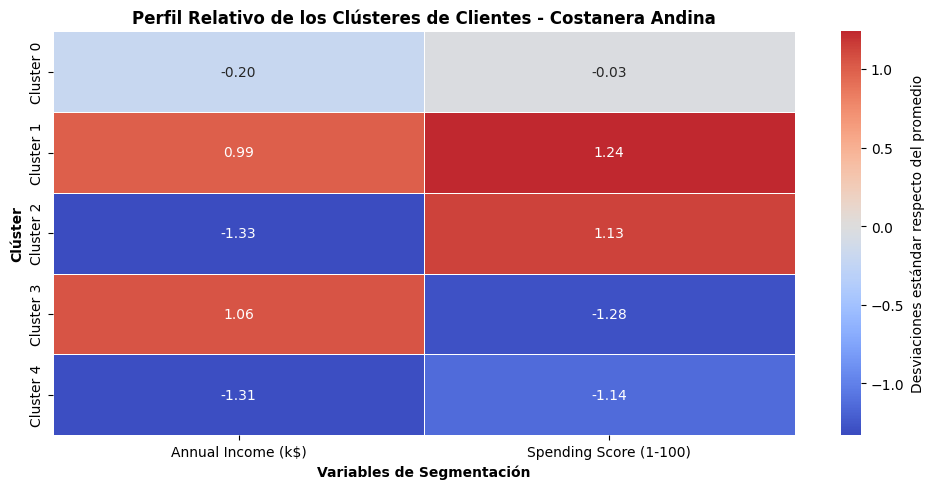

In [28]:
# =============================================================================
# MAPA DE CALOR DEL PERFIL DE LOS CLÚSTERES - COSTANERA ANDINA
# =============================================================================

"""
Visualización del perfil relativo de los clústeres de clientes mediante un mapa de calor.

¿QUÉ HACE ESTE CÓDIGO?

Este bloque representa gráficamente los centroides estandarizados obtenidos
por K-Means para la segmentación de clientes en el Centro Comercial Costanera Andina.

El procedimiento realiza los siguientes pasos:

1. Utiliza la tabla `centroides_estandarizados`, donde cada fila representa
   un clúster y cada columna una variable de segmentación (ej. Ingreso Anual y Spending Score).

2. Construye un mapa de calor en el que el color de cada celda representa
   qué tan por encima o por debajo del promedio general se encuentra una
   característica dentro de cada clúster.

3. Muestra dentro de cada celda el valor estandarizado correspondiente,
   redondeado a dos decimales.

4. Centra la escala de colores en 0 para diferenciar con claridad los valores
   superiores e inferiores al promedio poblacional.

¿CÓMO SE INTERPRETA EL MAPA?

Como los centroides fueron calculados sobre datos transformados mediante
`StandardScaler`, los valores se interpretan en desviaciones estándar
respecto del promedio general del dataset:

    - Valor cercano a 0 -> Característica similar al promedio general.
    - Valor positivo (+) -> Característica por encima del promedio general.
    - Valor negativo (-) -> Característica por debajo del promedio general.

¿PARA QUÉ SIRVE ESTE GRÁFICO?

El mapa de calor permite comparar rápidamente los perfiles de los clústeres
y detectar cuáles son las variables que más diferencian a cada segmento de clientes,
facilitando la traducción de los resultados técnicos a estrategias comerciales de negocio.
"""

plt.figure(
    figsize=(10, 5)
)

sns.heatmap(
    centroides_estandarizados,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5,
    cbar_kws={
        'label': 'Desviaciones estándar respecto del promedio'
    }
)

plt.title(
    'Perfil Relativo de los Clústeres de Clientes - Costanera Andina',
    fontweight='bold',
    fontsize=12
)

plt.xlabel(
    'Variables de Segmentación',
    fontweight='bold'
)

plt.ylabel(
    'Clúster',
    fontweight='bold'
)

plt.tight_layout()

plt.show()

### Conclusiones y Plan de Acción según el Mapa de Calor de Clústeres ($K=5$)

El análisis visual de los centroides estandarizados en el mapa de calor permite segmentar de forma descriptiva el comportamiento financiero y de consumo de los visitantes del Centro Comercial Costanera Andina, dividiéndolos en **5 perfiles claramente diferenciados**:

* **Clúster 0 (Ingreso y gasto medios):**
  * *Perfil:* Presentan ingresos ligeramente inferiores a la media (-0.20) y un puntaje de gasto neutral (-0.03). Corresponden al visitante estándar que acude al centro comercial de forma regular.
  * *Plan de Acción:* Mantener la oferta comercial general y asegurar promociones estandarizadas para mantener su frecuencia de visita.

* **Clúster 1 (Ingreso alto / gasto alto):**
  * *Perfil:* Altos ingresos (0.99) y un nivel de gasto muy elevado (1.24). Representan el segmento de mayor rentabilidad y valor para el centro comercial.
  * *Plan de Acción:* Implementar programas de beneficios exclusivos, experiencias de atención personalizada, áreas VIP y robustecer la oferta de tiendas de lujo y marcas de alta gama en la estrategia de distribución de espacios (*tenant mix*).

* **Clúster 2 (Ingreso bajo / gasto alto):**
  * *Perfil:* Ingresos bajos (-1.33) pero un puntaje de gasto alto (1.13). Son visitantes que destinan una alta proporción de sus recursos al consumo dentro del mall.
  * *Plan de Acción:* Fidelizarlos con beneficios de la tarjeta de fidelización y campañas en moda accesible, entretenimiento y tendencias juveniles. Cualquier facilidad de pago o financiamiento debe revisarla Administración con Asesoría legal para evitar el sobreendeudamiento (RR-012).

* **Clúster 3 (Ingreso alto / gasto bajo):**
  * *Perfil:* Altos ingresos (1.06) combinados con un puntaje de gasto muy bajo (-1.28). Tienen una gran capacidad financiera, pero muestran una baja propensión a gastar en el centro comercial.
  * *Plan de Acción:* No saturarlos con publicidad masiva de liquidaciones; en su lugar, diseñar estrategias basadas en la calidad, durabilidad, exclusividad y servicios de conveniencia que motiven su inversión.

* **Clúster 4 (Ingreso bajo / gasto bajo):**
  * *Perfil:* Bajos ingresos (-1.31) y bajo puntaje de gasto (-1.14). Poseen un presupuesto muy limitado y una participación reducida en el volumen de compras.
  * *Plan de Acción:* Optimizar la gestión operativa hacia alternativas masivas de bajo costo, enfocándose en servicios de utilidad pública, zonas de esparcimiento familiar y tiendas de conveniencia económica, sin reducir su acceso al resto de la oferta del centro (RR-010).

> **Nota:** estos planes son hipótesis para revisión humana de Marketing, Administración y Asesoría legal; no son decisiones automáticas ni definitivas.


## PCA completo

In [29]:
# =============================================================================
# PCA COMPLETO
# =============================================================================

"""
Aplicación de Análisis de Componentes Principales (PCA) sobre las
variables de segmentación estandarizadas.

¿QUÉ HACE ESTE CÓDIGO?

Este bloque aplica PCA sobre `X_cluster_scaled` con el objetivo de estudiar
cómo se distribuye la información contenida en las variables de segmentación.

El procedimiento realiza los siguientes pasos:

1. Crea un modelo PCA sin limitar inicialmente la cantidad de componentes.

2. Ajusta PCA utilizando `X_cluster_scaled`, es decir, el mismo conjunto de
   características estandarizadas que fue utilizado previamente por K-Means.

3. Transforma las variables originales en nuevos componentes principales.

4. Calcula cuánto porcentaje de la varianza total explica cada componente.

5. Calcula también la varianza explicada acumulada, que permite saber cuánta
   información se conserva al utilizar varios componentes en conjunto.

6. Organiza estos resultados en una tabla para facilitar su análisis.

¿QUÉ ES PCA?

PCA es una técnica de reducción de dimensionalidad.

Su objetivo es transformar las variables originales en nuevas variables
llamadas componentes principales.

Estos componentes se construyen como combinaciones de las características
originales y buscan concentrar la mayor cantidad posible de variabilidad
del dataset.

El primer componente principal explica la mayor cantidad posible de varianza.

El segundo componente explica la mayor cantidad posible de la varianza
restante, y así sucesivamente.

¿QUÉ ES LA VARIANZA EXPLICADA?

La varianza explicada indica qué proporción de la información del dataset
queda representada por cada componente principal.

Por ejemplo:

    PC1 = 25%

significa que el primer componente representa aproximadamente el 25% de la
variabilidad total presente en las variables de segmentación.

¿QUÉ ES LA VARIANZA ACUMULADA?

La varianza acumulada suma progresivamente la información explicada por los
componentes.

Por ejemplo:

    PC1 = 25%
    PC2 = 15%

implica que PC1 y PC2 juntos representan aproximadamente el 40% de la
varianza total.

Esto permite determinar cuántos componentes serían necesarios para conservar,
por ejemplo:

- 80% de la información;
- 90% de la información;
- 95% de la información.

¿POR QUÉ NO SE LIMITAN LOS COMPONENTES DESDE EL INICIO?

En esta etapa se utilizan todos los componentes posibles para poder estudiar
cómo se distribuye la varianza antes de decidir cuántos componentes podrían
ser suficientes para representar el dataset.

Esto evita seleccionar arbitrariamente una cantidad de dimensiones.

¿PARA QUÉ SE UTILIZA PCA EN ESTE ANÁLISIS?

PCA se utiliza principalmente para:

- estudiar la estructura dimensional del dataset;
- analizar la varianza explicada;
- identificar cuántos componentes concentran la mayor parte de la información;
- y posteriormente visualizar los clusters en un espacio reducido.

IMPORTANTE:

PCA NO se utiliza aquí para volver a crear los clusters.

Los clusters ya fueron obtenidos mediante K-Means utilizando las
variables de segmentación estandarizadas completas.

En esta etapa, PCA se utiliza como herramienta de análisis y visualización
posterior de la segmentación.
"""


# =============================================================================
# 1. CREAR PCA
# =============================================================================

pca_completo = PCA()


# =============================================================================
# 2. AJUSTAR Y TRANSFORMAR
# =============================================================================

X_pca_completo = pca_completo.fit_transform(
    X_cluster_scaled
)


# =============================================================================
# 3. VARIANZA EXPLICADA
# =============================================================================

varianza_explicada = (
    pca_completo
    .explained_variance_ratio_
)


varianza_acumulada = np.cumsum(
    varianza_explicada
)


# =============================================================================
# 4. TABLA DE RESULTADOS
# =============================================================================

df_varianza_pca = pd.DataFrame(
    {
        'componente': np.arange(
            1,
            len(varianza_explicada) + 1
        ),

        'varianza_explicada': varianza_explicada,

        'porcentaje_varianza': (
            varianza_explicada * 100
        ),

        'varianza_acumulada': varianza_acumulada,

        'porcentaje_acumulado': (
            varianza_acumulada * 100
        )
    }
)


# =============================================================================
# 5. MOSTRAR
# =============================================================================

print("=" * 85)
print("VARIANZA EXPLICADA POR PCA")
print("=" * 85)

display(
    df_varianza_pca.round(4)
)

VARIANZA EXPLICADA POR PCA


,componente,varianza_explicada,porcentaje_varianza,varianza_acumulada,porcentaje_acumulado
0,1,0.505,50.4951,0.505,50.4951
1,2,0.495,49.5049,1.000,100.0000


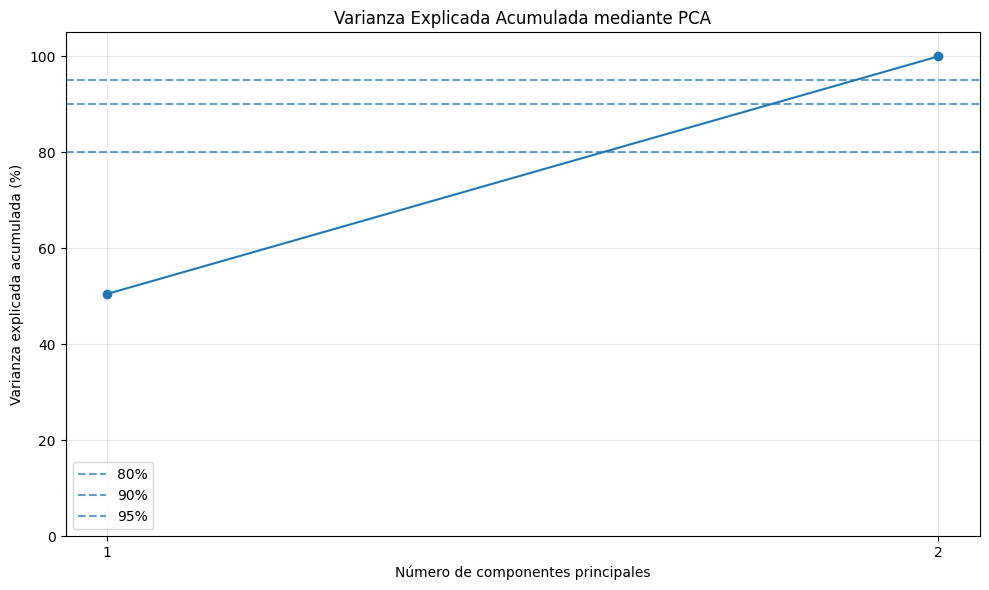

In [30]:
# =============================================================================
# VARIANZA EXPLICADA ACUMULADA
# =============================================================================

"""
Visualización de la varianza explicada acumulada mediante PCA.

¿QUÉ HACE ESTE CÓDIGO?

Este bloque genera un gráfico que muestra cómo aumenta el porcentaje de
varianza representada a medida que se incorporan más componentes principales.

El procedimiento realiza los siguientes pasos:

1. Utiliza la tabla `df_varianza_pca`, que contiene el porcentaje de varianza
   acumulada para cada cantidad de componentes.

2. Grafica en el eje horizontal el número de componentes principales.

3. Grafica en el eje vertical el porcentaje de varianza explicada acumulada.

4. Agrega tres líneas horizontales de referencia en:

       80%
       90%
       95%

   Estas líneas permiten identificar visualmente cuántos componentes son
   necesarios para alcanzar distintos niveles de representación de la
   información original.

¿QUÉ ES LA VARIANZA EXPLICADA ACUMULADA?

La varianza explicada acumulada representa la suma de la información aportada
por los componentes principales considerados hasta un determinado punto.

Por ejemplo:

    PC1 explica 25%
    PC2 explica 15%

significa que los dos primeros componentes explican conjuntamente
aproximadamente el 40% de la variabilidad total del dataset.

A medida que se agregan componentes, la varianza acumulada aumenta hasta
alcanzar finalmente el 100%.

¿CÓMO SE INTERPRETA EL GRÁFICO?

El gráfico permite observar cuántos componentes se necesitan para conservar
una determinada proporción de la información.

Por ejemplo, si la curva supera el 80% al utilizar 6 componentes, significa
que esos 6 componentes permiten representar al menos el 80% de la
variabilidad original.

Las líneas de referencia facilitan identificar los componentes necesarios
para alcanzar:

- 80% de la varianza;
- 90% de la varianza;
- 95% de la varianza.

¿PARA QUÉ SIRVE ESTE ANÁLISIS?

Este gráfico ayuda a evaluar si es posible reducir la cantidad de dimensiones
del dataset sin perder una proporción importante de información.

También permite determinar si una representación en solo dos componentes
principales es suficiente para describir la estructura completa de los datos.

IMPORTANTE:

En este análisis PCA se utiliza principalmente como herramienta de estudio y
visualización.

Los clusters ya fueron creados previamente mediante K-Means utilizando las
2 variables de segmentación estandarizadas.

Por lo tanto, el gráfico no modifica la segmentación obtenida; únicamente
permite evaluar cuánta información sería conservada al representar el dataset
con una cantidad menor de componentes principales.
"""


plt.figure(
    figsize=(10, 6)
)


plt.plot(
    df_varianza_pca['componente'],
    df_varianza_pca['porcentaje_acumulado'],
    marker='o'
)


# Líneas de referencia
plt.axhline(
    y=80,
    linestyle='--',
    alpha=0.7,
    label='80%'
)

plt.axhline(
    y=90,
    linestyle='--',
    alpha=0.7,
    label='90%'
)

plt.axhline(
    y=95,
    linestyle='--',
    alpha=0.7,
    label='95%'
)


plt.xticks(
    df_varianza_pca['componente']
)

plt.ylim(
    0,
    105
)

plt.xlabel(
    'Número de componentes principales'
)

plt.ylabel(
    'Varianza explicada acumulada (%)'
)

plt.title(
    'Varianza Explicada Acumulada mediante PCA'
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [31]:
# =============================================================================
# PESOS DE LAS VARIABLES EN LOS COMPONENTES PRINCIPALES
# =============================================================================

"""
Análisis de los pesos o cargas de las variables dentro de los componentes
principales generados mediante PCA.

¿QUÉ HACE ESTE CÓDIGO?

Este bloque permite identificar qué variables de segmentación tienen mayor
participación en la construcción de cada componente principal.

El procedimiento realiza los siguientes pasos:

1. Obtiene los coeficientes calculados por PCA mediante
   `pca_completo.components_`.

2. Transpone la matriz para que:
   - cada fila represente una variable de segmentación;
   - cada columna represente un componente principal.

3. Asigna los nombres originales de las variables a las filas.

4. Asigna nombres PC1, PC2, PC3, etc. a los componentes.

5. Organiza los resultados en una tabla para facilitar su interpretación.

¿QUÉ REPRESENTAN LOS PESOS?

Cada componente principal se construye como una combinación de las variables
originales.

Los pesos indican cuánto participa cada característica en esa combinación.

Por ejemplo, si dentro de PC1 aparecen valores como:

    Annual Income      +0.707
    Spending Score     -0.707


significa que `Annual Income` y `Spending Score` tienen igual participación
en la construcción de este componente, con signos opuestos (contraste ingreso-gasto).


¿CÓMO SE INTERPRETAN LOS VALORES?

Lo más importante para medir la participación de una variable es la magnitud
absoluta del coeficiente.

En términos generales:

    valor cercano a 0
        -> poca participación en ese componente.

    valor positivo alto
        -> participación importante en dirección positiva.

    valor negativo alto en magnitud
        -> participación importante, pero en dirección opuesta.

Por ejemplo:

    +0.70

y

    -0.70

representan una participación similar en importancia.

La diferencia está en la dirección de la relación con el componente.

¿QUÉ SIGNIFICA EL SIGNO?

El signo permite conocer la dirección en la que una variable se relaciona
con el componente.

Si dos variables tienen signos iguales dentro de un componente, tienden a
aportar en la misma dirección.

Si presentan signos opuestos, contribuyen en direcciones contrarias dentro
de ese componente.

IMPORTANTE:
Un coeficiente negativo NO significa que la variable sea negativa o poco
importante.

Para evaluar importancia se debe observar principalmente el valor absoluto
del coeficiente.

¿PARA QUÉ SIRVE ESTE ANÁLISIS?

Analizar los pesos permite comprender qué representa cada componente
principal y darle una interpretación basada en las variables de segmentación
originales.

Esto resulta especialmente útil para:

- identificar qué variables dominan PC1, PC2, PC3, etc.;
- comprender qué información resume cada componente;
- interpretar posteriormente los gráficos PCA;
- y explicar por qué determinados clusters aparecen separados en el espacio
  de componentes principales.

IMPORTANTE:

Los componentes principales no corresponden directamente a una sola
variable de segmentación.

Cada componente representa una combinación de varias variables, por lo que
su interpretación debe realizarse considerando conjuntamente aquellas que
presentan los mayores pesos en valor absoluto.
"""


# =============================================================================
# CREAR TABLA
# =============================================================================

pesos_pca = pd.DataFrame(
    pca_completo.components_.T,
    index=features_cluster,
    columns=[
        f'PC{i}'
        for i in range(
            1,
            len(features_cluster) + 1
        )
    ]
)


print("=" * 85)
print("PESOS DE LAS VARIABLES EN LOS COMPONENTES")
print("=" * 85)

display(
    pesos_pca.round(3)
)

PESOS DE LAS VARIABLES EN LOS COMPONENTES


,PC1,PC2
Annual Income (k$),0.707,0.707
Spending Score (1-100),0.707,-0.707


### Conclusiones sobre la Varianza Explicada y el Análisis de Componentes Principales (PCA)

* **Varianza Explicada por Componente:** El análisis de los componentes principales muestra que el primer componente (**PC1**) explica el **$50.49\%$** de la varianza total de los datos, mientras que el segundo componente (**PC2**) explica el **$49.50\%$** restante.

* **Acumulación de Varianza:** Juntos, ambos componentes alcanzan el **$100\%$** de la varianza acumulada, lo que indica que proyectar las variables sobre un espacio bidimensional no genera pérdida de información en comparación con el espacio original de dos dimensiones.

* **Pesos y Contribución de las Variables:** Al observar los pesos (*loadings*) de las características en cada componente:
  * En **PC1**, tanto *Annual Income* ($0.707$) como *Spending Score* ($0.707$) poseen cargas positivas idénticas, representando una dimensión general de escala o magnitud combinada.
  * En **PC2**, *Annual Income* ($0.707$) y *Spending Score* ($-0.707$) presentan magnitudes iguales pero signos opuestos, aislando la divergencia o contraste directo entre el nivel de ingresos y el comportamiento de gasto.
  
* **Utilidad Práctica:** Con solo dos variables, PCA retiene el 100 % de la varianza por construcción, por lo que no aporta evidencia sobre el número de clústeres; se usa únicamente para visualizar los segmentos en dos dimensiones.

In [32]:
# =============================================================================
# CENTROIDES EN UNIDADES ORIGINALES
# =============================================================================

"""
Conversión de los centroides de K-Means desde la escala estandarizada hacia
las unidades originales de las variables.
"""

# 1. Recuperar el StandardScaler desde el pipeline de preprocesamiento
scaler_cluster = (
    preprocessor_clustering
    .named_steps['scaler']
)

# 2. Aplicar la transformación inversa a los centroides
centroides_originales_array = (
    scaler_cluster
    .inverse_transform(
        kmeans_final.cluster_centers_
    )
)

# 3. Crear el DataFrame con las unidades originales
centroides_originales = pd.DataFrame(
    centroides_originales_array,
    columns=features_cluster,
    index=[
        f'Cluster {cluster_id}'
        for cluster_id in range(K_FINAL)
    ]
)

# 4. Mostrar resultados
print("=" * 90)
print("CENTROIDES EN UNIDADES ORIGINALES")
print("=" * 90)

display(
    centroides_originales.round(3)
)

CENTROIDES EN UNIDADES ORIGINALES


,Annual Income (k$),Spending Score (1-100)
Cluster 0,55.296,49.519
Cluster 1,86.538,82.128
Cluster 2,25.727,79.364
Cluster 3,88.200,17.114
Cluster 4,26.304,20.913


## Auditoría de perfil por clúster (edad y género no forman los grupos)

> Estas celdas se agregaron sin ejecutar. Ejecútalas y revisa los resultados antes de afirmar conclusiones sobre edad o género por segmento.

In [33]:
# =============================================================================
# AUDITORÍA DE PERFIL POR CLÚSTER
# =============================================================================

"""
Perfila cada clúster con variables que NO participaron en K-Means (edad, género
y categorías 'Unknown'), para revisar la representatividad de cada segmento.

Cómo leerlo: compara cada fila con la fila 'Total muestra'. Una diferencia
grande en edad o en % de mujeres describe el segmento, pero no prueba sesgo
por sí sola; la revisión la hace Marketing junto con el equipo.
"""

perfil_cluster = (
    df_resultados_cluster
    .groupby('cluster')
    .agg(
        n_clientes=('Age', 'size'),
        edad_media=('Age', 'mean'),
        edad_mediana=('Age', 'median'),
        pct_mujeres=('Gender', lambda s: (s == 'F').mean() * 100),
        pct_unknown_educacion=('Education', lambda s: (s == 'Unknown').mean() * 100),
        pct_unknown_estado_civil=('Marital Status', lambda s: (s == 'Unknown').mean() * 100),
    )
)

perfil_cluster['pct_clientes'] = perfil_cluster['n_clientes'] / len(df_resultados_cluster) * 100

total_muestra = pd.DataFrame(
    {
        'n_clientes': [len(df_resultados_cluster)],
        'edad_media': [df_resultados_cluster['Age'].mean()],
        'edad_mediana': [df_resultados_cluster['Age'].median()],
        'pct_mujeres': [(df_resultados_cluster['Gender'] == 'F').mean() * 100],
        'pct_unknown_educacion': [(df_resultados_cluster['Education'] == 'Unknown').mean() * 100],
        'pct_unknown_estado_civil': [(df_resultados_cluster['Marital Status'] == 'Unknown').mean() * 100],
        'pct_clientes': [100.0],
    },
    index=['Total muestra']
)

print("=" * 90)
print("PERFIL DE CADA CLÚSTER CON VARIABLES NO USADAS EN EL MODELO")
print("=" * 90)

display(pd.concat([perfil_cluster, total_muestra]).round(1))


PERFIL DE CADA CLÚSTER CON VARIABLES NO USADAS EN EL MODELO


,n_clientes,edad_media,edad_mediana,pct_mujeres,pct_unknown_educacion,pct_unknown_estado_civil,pct_clientes
0,81,42.7,46.0,59.3,14.8,6.2,40.5
1,39,32.7,32.0,53.8,10.3,5.1,19.5
2,22,25.3,23.5,59.1,27.3,18.2,11.0
3,35,41.1,42.0,45.7,2.9,2.9,17.5
4,23,45.2,46.0,60.9,13.0,13.0,11.5
Total muestra,200,38.8,36.0,56.0,13.0,7.5,100.0


## Visualización PCA 2 dimensiones

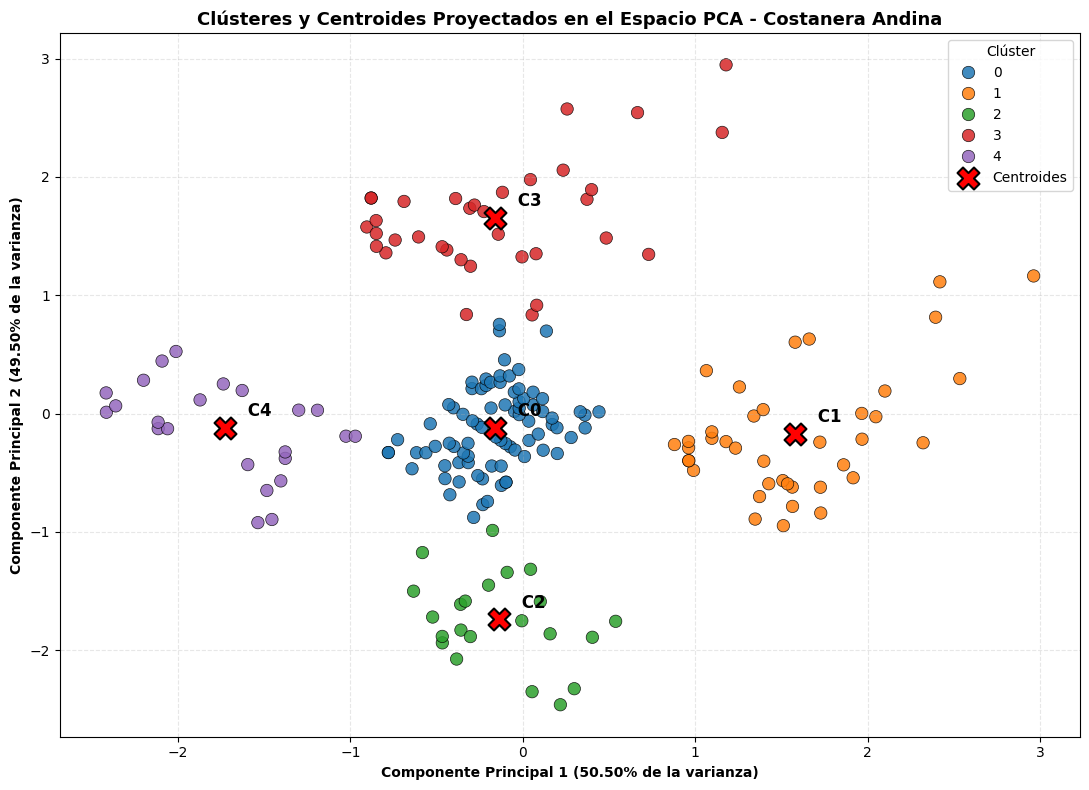

In [34]:
# =============================================================================
# REDUCCIÓN DIMENSIONAL CON PCA (2 COMPONENTES) Y PROYECCIÓN DE CENTROIDES
# =============================================================================

"""
Visualización de los clústeres y sus centroides dentro del espacio reducido
generado mediante PCA para los clientes del Centro Comercial Costanera Andina.
"""

# 1. Instanciar y ajustar PCA a 2 dimensiones si no estaba definido previamente
pca_2d = PCA(n_components=2, random_state=42)
X_pca = pca_2d.fit_transform(X_cluster_scaled)

# Crear DataFrame para el gráfico de dispersión de las observaciones
df_pca_plot = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_pca_plot['cluster'] = clusters

# 2. Proyectar los centroides originales sobre los dos componentes PCA
centroides_pca = pca_2d.transform(
    kmeans_final.cluster_centers_
)

# 3. Crear tabla con las coordenadas de los centroides
df_centroides_pca = pd.DataFrame(
    {
        'Cluster': [
            f'Cluster {cluster_id}'
            for cluster_id in range(K_FINAL)
        ],
        'Componente Principal 1': centroides_pca[:, 0],
        'Componente Principal 2': centroides_pca[:, 1]
    }
)

# 4. Crear figura
plt.figure(
    figsize=(11, 8)
)

# 5. Observaciones
sns.scatterplot(
    data=df_pca_plot,
    x='PC1',
    y='PC2',
    hue='cluster',
    palette='tab10',
    alpha=0.85,
    s=80,
    edgecolor='black',
    linewidth=0.5
)

# 6. Centroides
plt.scatter(
    centroides_pca[:, 0],
    centroides_pca[:, 1],
    marker='X',
    s=250,
    c='red',
    edgecolors='black',
    linewidths=1.5,
    label='Centroides',
    zorder=5
)

# 7. Etiquetar cada centroide
for cluster_id in range(K_FINAL):
    plt.text(
        centroides_pca[cluster_id, 0] + 0.1,
        centroides_pca[cluster_id, 1] + 0.1,
        f' C{cluster_id}',
        fontsize=12,
        fontweight='bold',
        color='black'
    )

# 8. Nombres claros de los ejes
plt.xlabel(
    f"Componente Principal 1 ({pca_2d.explained_variance_ratio_[0] * 100:.2f}% de la varianza)",
    fontweight='bold'
)

plt.ylabel(
    f"Componente Principal 2 ({pca_2d.explained_variance_ratio_[1] * 100:.2f}% de la varianza)",
    fontweight='bold'
)

plt.title(
    'Clústeres y Centroides Proyectados en el Espacio PCA - Costanera Andina',
    fontweight='bold',
    fontsize=13
)

plt.legend(
    title='Clúster'
)

plt.grid(
    alpha=0.3,
    linestyle='--'
)

plt.tight_layout()
plt.show()



## Conclusiones del Análisis Exploratorio y Diagnóstico Inicial (Proyecto Costanera Andina)

# FASE 6: Despliegue

## Prueba con datos sinteticos

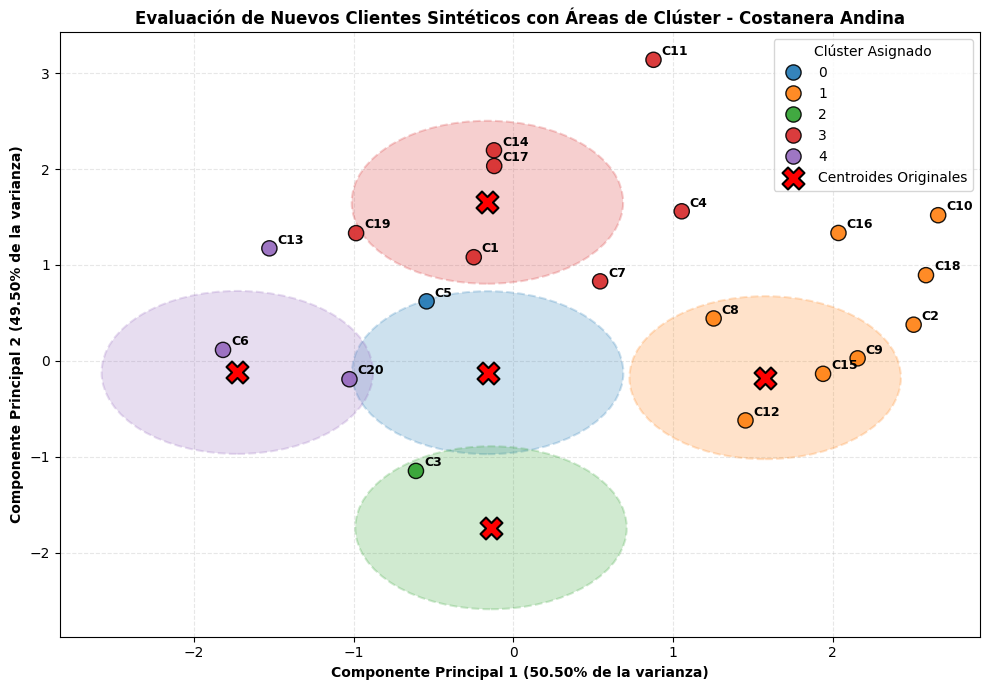

In [35]:
# =============================================================================
# PRUEBA DE SEGMENTACIÓN CON DATOS SINTÉTICOS Y VISUALIZACIÓN PCA (SIN DISPLAYS)
# =============================================================================
# 1. Cargar los datos sintéticos
url_sintetica = "https://raw.githubusercontent.com/YorkiOprogramador/costanera_andina/main/data/clientes_sinteticos_costanera.csv"
df_nuevo = pd.read_csv(url_sintetica)

# 2. Preparación de variables para el clustering
if 'CustomerID' in df_nuevo.columns:
    df_modelo = df_nuevo.drop(columns=['CustomerID'])
else:
    df_modelo = df_nuevo.copy()

df_modelo.columns = df_modelo.columns.str.strip()

features_cluster = ['Annual Income (k$)', 'Spending Score (1-100)']
X_nuevo = df_modelo[features_cluster]

# 3. Escalar y predecir (convertimos a .to_numpy() para evitar el UserWarning)
X_nuevo_scaled = scaler_cluster.transform(X_nuevo.to_numpy())
nuevos_clusters = kmeans_final.predict(X_nuevo_scaled)

df_nuevo['Cluster'] = nuevos_clusters

# =============================================================================
# 4. VISUALIZACIÓN DE LOS NUEVOS DATOS EN EL ESPACIO PCA CON ÁREAS DE CLÚSTER
# =============================================================================

# Proyectar los datos nuevos usando el objeto PCA ya ajustado (pca_2d)
X_nuevo_pca = pca_2d.transform(X_nuevo_scaled)

df_pca_nuevo = pd.DataFrame(X_nuevo_pca, columns=['PC1', 'PC2'])
df_pca_nuevo['Cluster'] = nuevos_clusters
df_pca_nuevo['CustomerID'] = df_nuevo['CustomerID']

plt.figure(figsize=(10, 7))

# Definir la paleta de colores utilizada por seaborn (tab10)
palette = sns.color_palette('tab10', K_FINAL)

# Obtener las coordenadas de los centroides originales en el espacio PCA
centroides_pca = pca_2d.transform(kmeans_final.cluster_centers_)

# Añadir círculos semitransparentes para distinguir el área de cada clúster
ax = plt.gca()
for cluster_id in range(K_FINAL):
    cx, cy = centroides_pca[cluster_id]
    color_cluster = palette[cluster_id]

    circle = plt.Circle(
        (cx, cy),
        radius=0.85,
        color=color_cluster,
        alpha=0.22,
        linestyle='--',
        linewidth=1.5,
        zorder=2
    )
    ax.add_patch(circle)

# Graficar los puntos nuevos de los clientes
sns.scatterplot(
    data=df_pca_nuevo,
    x='PC1',
    y='PC2',
    hue='Cluster',
    palette='tab10',
    s=120,
    edgecolor='black',
    linewidth=1,
    alpha=0.9,
    zorder=3
)

# Graficar los centroides originales como referencia principal
plt.scatter(
    centroides_pca[:, 0],
    centroides_pca[:, 1],
    marker='X',
    s=250,
    c='red',
    edgecolors='black',
    linewidths=1.5,
    label='Centroides Originales',
    zorder=5
)

# Anotar los ID de los clientes nuevos en el gráfico para trazabilidad
for _, row in df_pca_nuevo.iterrows():
    plt.text(
        row['PC1'] + 0.05,
        row['PC2'] + 0.05,
        f"C{int(row['CustomerID'])}",
        fontsize=9,
        fontweight='bold',
        zorder=4
    )

plt.xlabel(f"Componente Principal 1 ({pca_2d.explained_variance_ratio_[0]*100:.2f}% de la varianza)", fontweight='bold')
plt.ylabel(f"Componente Principal 2 ({pca_2d.explained_variance_ratio_[1]*100:.2f}% de la varianza)", fontweight='bold')
plt.title('Evaluación de Nuevos Clientes Sintéticos con Áreas de Clúster - Costanera Andina', fontweight='bold', fontsize=12)
plt.legend(title='Clúster Asignado')
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

In [36]:
print(f"Dimensiones del dataset sintético cargado: {df_nuevo.shape}")
display(df_nuevo.head())

Dimensiones del dataset sintético cargado: (20, 8)


,CustomerID,Gender,Age,Education,Marital Status,Annual Income (k$),Spending Score (1-100),Cluster
0,1,M,39,Uneducated,Divorced,76,26,3
1,2,F,19,College,Divorced,114,89,1
2,3,M,41,College,Married,28,60,2
3,4,M,61,High School,Divorced,109,41,3
4,5,M,47,Uneducated,Divorced,62,29,0


In [37]:
print("\nAsignación de Clústeres para los nuevos datos:")
display(df_nuevo[['CustomerID', 'Annual Income (k$)', 'Spending Score (1-100)', 'Cluster']])


Asignación de Clústeres para los nuevos datos:


,CustomerID,Annual Income (k$),Spending Score (1-100),Cluster
0,1,76,26,3
1,2,114,89,1
2,3,28,60,2
3,4,109,41,3
4,5,62,29,0
5,6,29,15,4
6,7,86,45,3
7,8,92,65,1
8,9,101,89,1
9,10,138,71,1


## Exportación final de artefactos y paquete ZIP

En esta etapa se consolida en una sola carpeta todo lo generado durante la segmentación. Se conservan los archivos de preprocesamiento exportados anteriormente y se agregan el modelo entrenado, los objetos PCA, las asignaciones de clúster, las tablas de evaluación, los centroides, la auditoría demográfica y las proyecciones utilizadas en las visualizaciones.

El paquete incluye gráficos en formato PNG. La celda final crea `archivos_segmentacion.zip`; en Google Colab inicia la descarga y, en Jupyter local, deja el ZIP en el directorio de trabajo.

In [38]:
# =============================================================================
# EXPORTACIÓN FINAL DE ARTEFACTOS Y EMPAQUETADO ZIP - COSTANERA ANDINA
# =============================================================================

"""
Consolida los datos preparados, el modelo K-Means, los objetos PCA, las
asignaciones de clúster, las métricas de evaluación y los resultados de apoyo.
Al final genera un ZIP con el contenido completo de la carpeta de exportación.
"""

# =============================================================================
# 1. VALIDAR QUE EL MODELADO Y LA EVALUACIÓN SE HAYAN EJECUTADO
# =============================================================================

objetos_requeridos = [
    'df',
    'X_cluster',
    'X_cluster_scaled_df',
    'preprocessor_clustering',
    'kmeans_final',
    'df_resultados_cluster',
    'df_evaluacion_k',
    'centroides_estandarizados',
    'centroides_originales',
    'pca_completo',
    'pca_2d',
    'df_varianza_pca',
    'df_pca_plot',
    'perfil_cluster',
    'K_FINAL',
    'K_ELBOW',
    'features_cluster'
]

objetos_faltantes = [
    nombre for nombre in objetos_requeridos
    if nombre not in globals()
]

if objetos_faltantes:
    raise NameError(
        'No se puede completar la exportación. Ejecuta primero las celdas '
        'de preparación, modelado, evaluación, PCA y auditoría. '
        f'Faltan: {objetos_faltantes}'
    )


# =============================================================================
# 2. CREAR / REUTILIZAR LA CARPETA DE EXPORTACIÓN
# =============================================================================

carpeta_exportacion = Path('archivos_segmentacion')
carpeta_exportacion.mkdir(parents=True, exist_ok=True)

# Identificador común para relacionar los CSV que contienen las mismas filas.
row_id = np.arange(len(df_resultados_cluster))

if not (
    len(X_cluster) == len(X_cluster_scaled_df)
    == len(df_resultados_cluster)
    == len(df_pca_plot)
):
    raise ValueError(
        'Los conjuntos original, escalado, resultado y PCA no tienen '
        'la misma cantidad de filas. Revisa la alineación antes de exportar.'
    )


# =============================================================================
# 3. EXPORTAR DATOS DE ENTRADA Y CONTEXTO
# =============================================================================

X_original_export = X_cluster.reset_index(drop=True).copy()
X_original_export.insert(0, 'row_id', row_id)

X_scaled_export = X_cluster_scaled_df.reset_index(drop=True).copy()
X_scaled_export.insert(0, 'row_id', row_id)

columnas_contexto = [
    'Age',
    'Gender',
    'Education',
    'Marital Status'
]
columnas_contexto = [
    columna for columna in columnas_contexto
    if columna in df_resultados_cluster.columns
]

contexto_segmentacion = (
    df_resultados_cluster[columnas_contexto]
    .reset_index(drop=True)
    .copy()
)
contexto_segmentacion.insert(0, 'row_id', row_id)

resultado_segmentacion = (
    df_resultados_cluster
    .reset_index(drop=True)
    .copy()
)
resultado_segmentacion.insert(0, 'row_id', row_id)

X_original_export.to_csv(
    carpeta_exportacion / 'X_segmentacion_original.csv',
    index=False,
    encoding='utf-8-sig'
)

X_scaled_export.to_csv(
    carpeta_exportacion / 'X_segmentacion_escalado.csv',
    index=False,
    encoding='utf-8-sig'
)

contexto_segmentacion.to_csv(
    carpeta_exportacion / 'contexto_segmentacion.csv',
    index=False,
    encoding='utf-8-sig'
)

resultado_segmentacion.to_csv(
    carpeta_exportacion / 'resultado_segmentacion.csv',
    index=False,
    encoding='utf-8-sig'
)


# =============================================================================
# 4. GUARDAR MODELOS Y PIPELINES REUTILIZABLES
# =============================================================================

joblib.dump(
    preprocessor_clustering,
    carpeta_exportacion / 'preprocessor_clustering.joblib'
)

joblib.dump(
    kmeans_final,
    carpeta_exportacion / 'kmeans_final.joblib'
)

joblib.dump(
    pca_completo,
    carpeta_exportacion / 'pca_completo.joblib'
)

joblib.dump(
    pca_2d,
    carpeta_exportacion / 'pca_2d.joblib'
)


# =============================================================================
# 5. EXPORTAR TABLAS DE EVALUACIÓN, CENTROIDES Y AUDITORÍA
# =============================================================================

df_evaluacion_k.to_csv(
    carpeta_exportacion / 'evaluacion_kmeans.csv',
    index=False,
    encoding='utf-8-sig'
)

centroides_estandarizados.to_csv(
    carpeta_exportacion / 'centroides_estandarizados.csv',
    index_label='cluster',
    encoding='utf-8-sig'
)

centroides_originales.to_csv(
    carpeta_exportacion / 'centroides_originales.csv',
    index_label='cluster',
    encoding='utf-8-sig'
)

df_varianza_pca.to_csv(
    carpeta_exportacion / 'varianza_explicada_pca.csv',
    index=False,
    encoding='utf-8-sig'
)

perfil_cluster.to_csv(
    carpeta_exportacion / 'perfil_demografico_por_cluster.csv',
    index_label='cluster',
    encoding='utf-8-sig'
)

# Tabla PCA de los registros usados en el entrenamiento.
df_pca_export = df_pca_plot.reset_index(drop=True).copy()
df_pca_export.insert(0, 'row_id', row_id)
df_pca_export.to_csv(
    carpeta_exportacion / 'proyeccion_pca_clientes.csv',
    index=False,
    encoding='utf-8-sig'
)

# Si se ejecutó la prueba con clientes sintéticos, se exporta por separado.
if 'df_nuevo' in globals() and 'Cluster' in df_nuevo.columns:
    df_nuevo.to_csv(
        carpeta_exportacion / 'clientes_sinteticos_segmentados.csv',
        index=False,
        encoding='utf-8-sig'
    )

if 'df_pca_nuevo' in globals():
    df_pca_nuevo.to_csv(
        carpeta_exportacion / 'proyeccion_pca_clientes_sinteticos.csv',
        index=False,
        encoding='utf-8-sig'
    )

# Exportar el resumen de valores atípicos del EDA si fue calculado.
if 'df_outliers_resumen' in globals():
    df_outliers_resumen.to_csv(
        carpeta_exportacion / 'resumen_outliers_eda.csv',
        index=False,
        encoding='utf-8-sig'
    )


# =============================================================================
# 6. GENERAR GRÁFICOS EN PNG PARA CONSULTA FUERA DEL NOTEBOOK
# =============================================================================

# 6.1 Inercia / método del codo.
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    df_evaluacion_k['k'],
    df_evaluacion_k['inercia'],
    marker='o'
)
ax.axvline(
    K_FINAL,
    linestyle='--',
    alpha=0.7,
    label=f'K seleccionado = {K_FINAL}'
)
ax.set(
    title='Evaluación de inercia - Método del Codo',
    xlabel='Número de clústeres (K)',
    ylabel='Inercia'
)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(
    carpeta_exportacion / 'evaluacion_metodo_codo.png',
    dpi=180,
    bbox_inches='tight'
)
plt.close(fig)

# 6.2 Silhouette Score.
df_silhouette_export = df_evaluacion_k.dropna(
    subset=['silhouette']
).copy()
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    df_silhouette_export['k'],
    df_silhouette_export['silhouette'],
    marker='o'
)
ax.axvline(
    K_FINAL,
    linestyle='--',
    alpha=0.7,
    label=f'K seleccionado = {K_FINAL}'
)
ax.set(
    title='Silhouette Score por cantidad de clústeres',
    xlabel='Número de clústeres (K)',
    ylabel='Silhouette Score'
)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(
    carpeta_exportacion / 'evaluacion_silhouette.png',
    dpi=180,
    bbox_inches='tight'
)
plt.close(fig)

# 6.3 Mapa de calor de centroides estandarizados.
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(
    centroides_estandarizados,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5,
    cbar_kws={
        'label': 'Desviaciones estándar respecto del promedio'
    },
    ax=ax
)
ax.set_title('Perfil estandarizado de los clústeres - Costanera Andina')
ax.set_xlabel('Variables de segmentación')
ax.set_ylabel('Clúster')
fig.tight_layout()
fig.savefig(
    carpeta_exportacion / 'mapa_calor_centroides.png',
    dpi=180,
    bbox_inches='tight'
)
plt.close(fig)

# 6.4 Proyección PCA de los clientes y centroides.
centroides_pca_export = pca_2d.transform(
    kmeans_final.cluster_centers_
)
fig, ax = plt.subplots(figsize=(9, 7))
sns.scatterplot(
    data=df_pca_export,
    x='PC1',
    y='PC2',
    hue='cluster',
    palette='tab10',
    s=65,
    alpha=0.85,
    edgecolor='black',
    linewidth=0.35,
    ax=ax
)
ax.scatter(
    centroides_pca_export[:, 0],
    centroides_pca_export[:, 1],
    marker='X',
    s=220,
    c='red',
    edgecolors='black',
    linewidths=1.2,
    label='Centroides',
    zorder=5
)
ax.set_title('Clústeres y centroides proyectados en PCA')
ax.set_xlabel(
    f"PC1 ({pca_2d.explained_variance_ratio_[0] * 100:.2f}% de varianza)"
)
ax.set_ylabel(
    f"PC2 ({pca_2d.explained_variance_ratio_[1] * 100:.2f}% de varianza)"
)
ax.grid(alpha=0.3, linestyle='--')
ax.legend(title='Clúster')
fig.tight_layout()
fig.savefig(
    carpeta_exportacion / 'visualizacion_clusters_pca.png',
    dpi=180,
    bbox_inches='tight'
)
plt.close(fig)

# 6.5 Varianza explicada acumulada por PCA.
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    df_varianza_pca['componente'],
    df_varianza_pca['porcentaje_acumulado'],
    marker='o'
)
for porcentaje in [80, 90, 95]:
    ax.axhline(
        y=porcentaje,
        linestyle='--',
        alpha=0.6,
        label=f'{porcentaje}%'
    )
ax.set(
    title='Varianza explicada acumulada mediante PCA',
    xlabel='Número de componentes principales',
    ylabel='Varianza acumulada (%)',
    ylim=(0, 105)
)
ax.set_xticks(df_varianza_pca['componente'])
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(
    carpeta_exportacion / 'varianza_acumulada_pca.png',
    dpi=180,
    bbox_inches='tight'
)
plt.close(fig)


# =============================================================================
# 7. METADATOS Y DOCUMENTACIÓN DEL PAQUETE
# =============================================================================

fila_mejor_silhouette = (
    df_silhouette_export.loc[
        df_silhouette_export['silhouette'].idxmax()
    ]
)

metadatos_modelo = {
    'proyecto': 'Segmentación de clientes - Costanera Andina',
    'fecha_exportacion': pd.Timestamp.now().isoformat(),
    'dataset': 'Mall Customers.xlsx - muestra de referencia de 200 registros',
    'advertencia_dataset': (
        'La muestra es una prueba de concepto y no acredita que sean '
        'registros reales del Centro Comercial Costanera Andina.'
    ),
    'algoritmo': 'KMeans',
    'numero_clusters': int(K_FINAL),
    'variables_modelado': list(features_cluster),
    'n_observaciones': int(len(df_resultados_cluster)),
    'parametros_modelo': {
        'init': 'k-means++',
        'n_init': 20,
        'max_iter': 500,
        'random_state': 42
    },
    'inercia_final': float(kmeans_final.inertia_),
    'iteraciones': int(kmeans_final.n_iter_),
    'k_sugerido_elbow': int(K_ELBOW),
    'k_mejor_silhouette': int(fila_mejor_silhouette['k']),
    'silhouette_maximo': float(fila_mejor_silhouette['silhouette']),
    'nota_pca': (
        'PCA se utiliza para análisis y visualización; no participa en '
        'la asignación de clústeres.'
    )
}

with open(
    carpeta_exportacion / 'metadatos_modelo.json',
    'w',
    encoding='utf-8'
) as archivo_json:
    json.dump(
        metadatos_modelo,
        archivo_json,
        ensure_ascii=False,
        indent=4
    )

"""
# Artefactos de segmentación - Costanera Andina

Este paquete reúne los archivos generados por el notebook de segmentación K-Means.

## Datos y resultados

- `X_segmentacion_original.csv`: variables utilizadas para segmentar, en sus escalas originales.
- `X_segmentacion_escalado.csv`: las mismas variables después del pipeline de imputación y estandarización.
- `contexto_segmentacion.csv`: variables demográficas reservadas para caracterización; no se utilizaron para calcular distancias.
- `resultado_segmentacion.csv`: muestra analizada con la etiqueta de clúster asignada.
- `evaluacion_kmeans.csv`: inercia y Silhouette Score para los valores de K evaluados.
- `centroides_estandarizados.csv`: centroides expresados en desviaciones estándar.
- `centroides_originales.csv`: centroides expresados en las unidades originales de ingreso y Spending Score.
- `perfil_demografico_por_cluster.csv`: resumen de edad, género y categorías desconocidas por clúster.
- `varianza_explicada_pca.csv`: varianza explicada y acumulada por componente principal.
- `proyeccion_pca_clientes.csv`: coordenadas PC1 y PC2 de la muestra, con su clúster.
- `clientes_sinteticos_segmentados.csv` y `proyeccion_pca_clientes_sinteticos.csv`: se incluyen si se ejecutó la prueba de asignación con datos sintéticos.
- `resumen_outliers_eda.csv`: se incluye si la tabla de outliers fue generada en el EDA.

## Modelos serializados

- `preprocessor_clustering.joblib`: pipeline de imputación y StandardScaler.
- `kmeans_final.joblib`: modelo K-Means ajustado.
- `pca_completo.joblib`: PCA ajustado para el análisis de varianza.
- `pca_2d.joblib`: PCA de dos componentes utilizado para visualización.

Los archivos `.joblib` deben cargarse únicamente desde fuentes confiables y usando versiones compatibles de las bibliotecas de Python.

## Gráficos

Se incluyen PNG de la evaluación de K, mapa de calor de centroides, proyección PCA y varianza acumulada.
"""


# =============================================================================
# 8. VALIDAR ARCHIVOS Y CREAR EL ZIP
# =============================================================================

archivos_generados = sorted(
    archivo.name
    for archivo in carpeta_exportacion.iterdir()
    if archivo.is_file()
)

if not archivos_generados:
    raise RuntimeError('La carpeta de exportación está vacía.')

ruta_zip = Path(
    shutil.make_archive(
        base_name=str(Path.cwd() / 'archivos_segmentacion'),
        format='zip',
        root_dir=str(carpeta_exportacion)
    )
)

with zipfile.ZipFile(ruta_zip, 'r') as paquete:
    archivo_danado = paquete.testzip()
    if archivo_danado is not None:
        raise RuntimeError(
            f'El ZIP contiene un archivo dañado: {archivo_danado}'
        )
    archivos_en_zip = paquete.namelist()

print('=' * 85)
print('EXPORTACIÓN Y EMPAQUETADO COMPLETADOS - COSTANERA ANDINA')
print('=' * 85)
print(f'Carpeta de artefactos: {carpeta_exportacion.resolve()}')
print(f'ZIP generado: {ruta_zip.resolve()}')
print(f'Cantidad de archivos incluidos: {len(archivos_en_zip)}')
print('\nContenido del paquete:')
for nombre_archivo in archivos_en_zip:
    print(f' - {nombre_archivo}')

# Descarga automática en Colab; en Jupyter local el ZIP queda en el directorio actual.
if colab_files is not None:
    colab_files.download(str(ruta_zip))
else:
    print('\nEntorno local detectado: el ZIP quedó guardado en la ruta indicada.')


EXPORTACIÓN Y EMPAQUETADO COMPLETADOS - COSTANERA ANDINA
Carpeta de artefactos: /content/archivos_segmentacion
ZIP generado: /content/archivos_segmentacion.zip
Cantidad de archivos incluidos: 24

Contenido del paquete:
 - kmeans_final.joblib
 - evaluacion_silhouette.png
 - visualizacion_clusters_pca.png
 - metadatos_modelo.json
 - evaluacion_kmeans.csv
 - contexto_segmentacion.csv
 - resumen_outliers_eda.csv
 - evaluacion_metodo_codo.png
 - mapa_calor_centroides.png
 - resultado_segmentacion.csv
 - centroides_originales.csv
 - proyeccion_pca_clientes.csv
 - perfil_demografico_por_cluster.csv
 - X_segmentacion_original.csv
 - README_EXPORTACION.md
 - varianza_acumulada_pca.png
 - clientes_sinteticos_segmentados.csv
 - pca_completo.joblib
 - preprocessor_clustering.joblib
 - X_segmentacion_escalado.csv
 - centroides_estandarizados.csv
 - proyeccion_pca_clientes_sinteticos.csv
 - varianza_explicada_pca.csv
 - pca_2d.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [40]:

# =============================================================================
# EXPORTACIÓN DATASET PROCESADO - COSTANERA ANDINA
# =============================================================================

# 1. Validar DataFrame
if "df" not in globals():
    raise NameError("No existe el DataFrame 'df'. Ejecuta primero las celdas anteriores.")

# 2. Preparar dataset procesado
mall_customer_procesado = df.copy()

# Normalizar nombres de columnas
mall_customer_procesado.columns = (
    mall_customer_procesado.columns.str.strip()
)

# 3. Crear carpeta de exportación
carpeta = Path("exportacion_costanera")
carpeta.mkdir(parents=True, exist_ok=True)

# 4. Exportar CSV
nombre_csv = "mall_customer_procesed.csv"
ruta_csv = carpeta / nombre_csv

mall_customer_procesado.to_csv(
    ruta_csv,
    index=False,
    encoding="utf-8-sig"
)

# 5. Crear ZIP con únicamente el CSV
ruta_zip = Path("mall_customer_procesed.zip")

with zipfile.ZipFile(
    ruta_zip,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archivo_zip:

    archivo_zip.write(
        ruta_csv,
        arcname=nombre_csv
    )

# 6. Validar ZIP
with zipfile.ZipFile(ruta_zip, "r") as archivo_zip:
    assert archivo_zip.testzip() is None
    print("Contenido del ZIP:", archivo_zip.namelist())

# 7. Resumen
print("\nEXPORTACIÓN COMPLETADA")
print(f"Registros: {len(mall_customer_procesado)}")
print(f"Columnas: {len(mall_customer_procesado.columns)}")
print(f"CSV: {ruta_csv.resolve()}")
print(f"ZIP: {ruta_zip.resolve()}")

# 8. Descargar en Google Colab
try:
    from google.colab import files
    files.download(str(ruta_zip))
except ImportError:
    print("ZIP guardado en el directorio de trabajo.")


Contenido del ZIP: ['mall_customer_procesed.csv']

EXPORTACIÓN COMPLETADA
Registros: 200
Columnas: 6
CSV: /content/exportacion_costanera/mall_customer_procesed.csv
ZIP: /content/mall_customer_procesed.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Conclusión y consideraciones éticas

## 1. Aplicación e Importancia de la Metodología CRISP-DM
La implementación del estándar **CRISP-DM** resultó fundamental para estructurar el trabajo de forma iterativa, ordenada y alineada con los objetivos comerciales dentro del plazo de 4 meses:

* **Fase 1: Comprensión del Negocio:** Permitió traducir la problemática operativa del centro comercial (campañas genéricas de baja conversión, desconocimiento de nichos rentables y asignación intuitiva de locales) en un objetivo analítico claro: segmentar a los visitantes mediante aprendizaje no supervisado para personalizar el marketing y optimizar el *tenant mix*.
* **Fase 2: Comprensión de los Datos:** Garantizó una ingesta segura mediante validación criptográfica **SHA-256** del archivo `Mall Customers.xlsx` (200 registros únicos y 7 columnas iniciales). El Análisis Exploratorio de Datos (EDA) permitió auditar la calidad estructural, descubrir datos faltantes encubiertos bajo la etiqueta `'Unknown'` y confirmar visualmente la existencia de agrupaciones naturales.
* **Fase 3: Preparación de los Datos:** Fue clave para evitar distorsiones matemáticas en el algoritmo basado en distancias. Se normalizaron encabezados, se eliminó la variable secuencial `CustomerID`, se separaron las variables demográficas sensibles para auditoría y se construyó un *pipeline* automatizado con imputación preventiva (`SimpleImputer`) y estandarización de escalas (`StandardScaler`).
* **Fase 4: Modelado:** Posibilitó el entrenamiento objetivo del algoritmo **K-Means** utilizando variables de comportamiento y capacidad adquisitiva (`Annual Income` y `Spending Score`), aislando perfiles sin introducir sesgos discriminatorios directos.
* **Fase 5: Evaluación:** Permitió seleccionar **K = 5** con el Método del Codo y el Coeficiente de Silueta (0,5547). Quedan pendientes la prueba de estabilidad, la auditoría de equidad por segmento y la validación comercial con Marketing.
* **Fase 6: Despliegue:** Conecta el modelo con la operación real mediante el almacenamiento de artefactos (`joblib`), el diseño de un *dashboard* interactivo y la entrega de un plan de acción comercial supervisado.

---

## 2. Resultados Obtenidos e Interpretación Técnica
* **Diagnóstico Demográfico y Estadístico:** La muestra de 200 clientes presenta una edad promedio de **38.85 años** (rango de 18 a 70 años), un ingreso anual medio de **60.56 mil USD** (rango de 15 a 137 mil USD) y un índice de gasto (*Spending Score*) promedio de **50.20 puntos** (mediana de 50.0). Demográficamente, existe una mayor proporción de mujeres (**56.0%**), personas casadas (**56.0%**) y profesionales graduados (**33.5%**).
* **Tratamiento de Valores Faltantes y *Outliers*:** Aunque no existen nulos explícitos (`NaN`), se identificó un **13.0%** de registros `'Unknown'` en `Education` (26 casos) y un **7.5%** en `Marital Status` (15 casos), los cuales se conservaron para no perder registros válidos de ingreso y gasto. Mediante el criterio intercuartílico (`1.5 × IQR`), solo se detectaron **2 valores atípicos** en `Annual Income` (137 mil USD), que fueron retenidos y escalados para representar fielmente al segmento de alto patrimonio.
* **Correlación y Patrones Multivariados:** La matriz de correlación de Pearson demostró independencia lineal entre ingreso y gasto (`r ≈ 0.01`), descartando multicolinealidad, además de una correlación negativa moderada entre la edad y el puntaje de gasto (`r = -0.33`), evidenciando que los puntajes de gasto superiores a 70 se concentran en visitantes menores de 40 años.
* **Definición de K = 5 y Reducción Dimensional (PCA):** La evaluación conjunta de la curva de inercia (Método del Codo) y el **Silhouette Score** confirmó que **K = 5** es la estructura más consistente entre los K evaluados. Con dos variables, PCA retiene el **100 % de la varianza** por construcción (PC1 50,49 % y PC2 49,50 %), por lo que se usa solo para visualizar.

---

## 3. Implicancias Estratégicas para el Negocio
* **Transición del Marketing Masivo a la Personalización:** El centro comercial deja atrás las campañas genéricas de bajo retorno, permitiendo dirigir el presupuesto publicitario hacia acciones específicas según la propensión real de gasto de cada grupo.
* **Identificación del Valor y Riesgo de Fuga:** La segmentación visibiliza tanto a los clientes que sostienen el flujo de caja actual como a aquellos con alta capacidad financiera que hoy no convierten dentro del recinto, abriendo una oportunidad directa de captura de valor.
* **Impacto económico:** este notebook no lo estima; el retorno comercial debe medirse con datos reales después de la validación de Marketing.

---

## 4. Caracterización y Plan de Acción por Clúster (K = 5)
A partir del análisis de centroides estandarizados y mapas de calor, se establecen cinco perfiles con estrategias diferenciadas:

* **Clúster 0 · Ingreso y gasto medios (Ingreso: -0.20 | Gasto: -0.03):**
  * *Interpretación:* Visitantes de ingresos medios y comportamiento de gasto moderado; constituyen la base más numerosa y estable del flujo peatonal del centro comercial.
  * *Plan de Acción:* Mantener campañas estacionales transversales, programas de acumulación de puntos estándar y eventos familiares que aseguren su recurrencia de visita.
* **Clúster 1 · Ingreso alto / gasto alto (Ingreso: 0.99 | Gasto: 1.24):**
  * *Interpretación:* Segmento de alto poder adquisitivo y máxima propensión al gasto; representa el nicho de mayor rentabilidad directa.
  * *Plan de Acción:* Desplegar estrategias de fidelización VIP (estacionamiento preferencial, *lounges* exclusivos, preventas privadas y *personal shoppers*), priorizando la retención y la experiencia personalizada.
* **Clúster 2 · Ingreso bajo / gasto alto (Ingreso: -1.33 | Gasto: 1.13):**
  * *Interpretación:* Clientes con ingresos bajos (su perfil etario se verifica en la celda de auditoría por clúster) pero un índice de gasto muy elevado dentro del recinto.
  * *Plan de Acción:* Enfocar campañas digitales y promociones en moda rápida, tecnología y entretenimiento; cualquier alianza de pago en cuotas se revisa con Administración y Asesoría legal para evitar el sobreendeudamiento (RR-012).
* **Clúster 3 · Ingreso alto / gasto bajo (Ingreso: 1.06 | Gasto: -1.28):**
  * *Interpretación:* Visitantes con alta solvencia económica pero muy baja conversión de compra actual en el mall (oportunidad latente de crecimiento).
  * *Plan de Acción:* Evitar promociones masivas de liquidación; dirigir comunicaciones enfocadas en propuesta de valor, calidad certificada, gastronomía de autor y servicios especializados que justifiquen su decisión de compra.
* **Clúster 4 · Ingreso bajo / gasto bajo (Ingreso: -1.31 | Gasto: -1.14):**
  * *Interpretación:* Visitantes con presupuesto restringido y baja participación transaccional.
  * *Plan de Acción:* Ofrecer promociones de canasta básica, cuponeras de descuento directo en días de menor flujo y acceso a servicios esenciales sin barreras de entrada.

---

## 5. Optimización de la Distribución de Tiendas (*Tenant Mix*)
Los hallazgos del modelo permiten respaldar decisiones inmobiliarias y de asignación de espacios comerciales basadas en evidencia:

* **Zonas de Lujo y Gastronomía *Premium*:** Consolidar sectores exclusivos con marcas de alta gama, tiendas de especialidad y restaurantes *gourmet* orientados a fidelizar al **Clúster 1** y atraer el gasto retenido del **Clúster 3**.
* **Polos Juveniles y de Tendencia Rápida:** Ubicar tiendas de *fast fashion*, artículos deportivos, tecnología, *gaming* y comida rápida en áreas de alto tránsito y visibilidad para capitalizar el dinamismo del **Clúster 2**.
* **Anclas Comerciales y Servicios Integrales:** Distribuir estratégicamente tiendas departamentales, supermercados, farmacias, servicios públicos y plazas de entretenimiento familiar para sostener el flujo continuo de los **Clústeres 0 y 4**, optimizando la ocupación y el valor por metro cuadrado del recinto.

* **Cautela:** estas ubicaciones son hipótesis; no deben reducir la oferta accesible para los clústeres de ingreso bajo (RR-010) y requieren revisión humana de Marketing, Administración y Asesoría legal.

---

## 6. Consideraciones Éticas, Legales y de Gobernanza
El desarrollo técnico se ejecutó bajo los principios de **Justicia, Transparencia, Privacidad y Responsabilidad**:

* **Cumplimiento Legal y Privacidad (Ley 19.628):** La integridad de la fuente se verificó con **SHA-256** y se eliminó el identificador directo (`CustomerID`); esto no equivale a cumplimiento legal: la licitud, el consentimiento informado y la seudonimización formal los revisan TI y Legal antes de usar datos reales.
* **Prevención de Discriminación Algorítmica:** Las variables demográficas sensibles (`Gender`, `Education`, `Marital Status`) fueron excluidas del cálculo matemático de distancias de K-Means, utilizándose solo *a posteriori* para auditar la representatividad de cada segmento (ver celda de auditoría por clúster); la ausencia de sesgos no está confirmada hasta ejecutarla y revisarla con Marketing.
* **Mitigación del Sesgo de Exclusión y Muestreo:** No se eliminaron los registros extremos de ingresos ni a los adultos mayores durante la limpieza de datos para no invisibilizar minorías demográficas. Asimismo, se documentó la necesidad de complementar los registros de fidelización con conteos de aforo peatonal general para incluir a compradores no bancarizados o que pagan en efectivo.
* **Supervisión Humana:** Se establece que los clústeres constituyen hipótesis analíticas y no determinaciones automáticas de precios individuales; toda campaña o ajuste del *tenant mix* requiere validación humana por parte del comité de Marketing y Asesoría Legal. El monitoreo posterior al cierre (deriva de datos) queda fuera del alcance y requeriría un nuevo acuerdo.